In [ ]:
!pip install -q \
    transformers==4.44.2 \
    tokenizers==0.19.1 \
    huggingface-hub==0.24.7 \
    datasets \
    joblib \
    scikit-learn \
    scipy \
    ushuffle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 117.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 124.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.5/417.5 kB 38.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.39.0 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 0.24.7 which is incompatible.
peft 0.19.1 requires huggingface_hub>=0.25.0, but you have huggingface-hub 0.24.7 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.24.7 which is incompatible.


# Promoter Causal Interventions in Baseline DNABERT-2

## Objective

Test whether candidate components identified in Notebook 3 can restore promoter-associated evidence when clean activations are patched into matched corrupted promoter sequences.

## Primary causal question

Are L1H9, L1H2, L2H9, Layer-1 attention, and Layer-1 MLP merely associated with the Layer-5 promoter representation, or can their clean activations causally rescue that representation in a corrupted run?

## Main metric

Recovery fraction:

\[
\text{Recovery}
=
\frac{\text{patched logit} - \text{corrupt logit}}
{\text{clean logit} - \text{corrupt logit}}
\]

Interpretation:

- 0: no rescue
- 1: full rescue
- between 0 and 1: partial rescue
- above 1: over-restoration
- below 0: patching worsens the corrupted representation

## Primary corruption

Exact dinucleotide-preserving shuffling, because it preserves adjacent-base statistics while disrupting longer motifs and higher-order organization.

## Interpretation boundary

The measured output remains a fixed Layer-5 diagnostic probe, not a native DNABERT-2 promoter classifier.

# Cell 1 — Verify compatible package versions

In [ ]:
import torch
import transformers
import tokenizers
import huggingface_hub

print("Torch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu128
Transformers: 4.44.2
Tokenizers: 0.19.1
Hugging Face Hub: 0.24.7
CUDA available: True


# Cell 2 — Imports, reproducibility, and saved artifacts

In [ ]:
from pathlib import Path
from collections import Counter
import random
import joblib

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset, Dataset
from google.colab import drive

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/algoverse/dnabert"
)

BASELINE_DIR = (
    PROJECT_DIR / "outputs/promoter_baseline_pilot"
)

BEHAVIOR_DIR = (
    PROJECT_DIR / "outputs/promoter_behavioral_localization"
)

COMPONENT_DIR = (
    PROJECT_DIR / "outputs/promoter_component_localization"
)

CAUSAL_DIR = (
    PROJECT_DIR / "outputs/promoter_causal_interventions"
)

CAUSAL_DIR.mkdir(parents=True, exist_ok=True)

PROBE_PATH = (
    BASELINE_DIR / "dnabert_layer5_probe.joblib"
)

HETEROGENEITY_PATH = (
    BEHAVIOR_DIR / "promoter_heterogeneity_results.csv"
)

HEAD_MEANS_PATH = (
    COMPONENT_DIR / "attention_head_reference_means.pt"
)

BRANCH_MEANS_PATH = (
    COMPONENT_DIR / "branch_reference_means.pt"
)

required_paths = {
    "Layer-5 probe": PROBE_PATH,
    "Promoter heterogeneity table": HETEROGENEITY_PATH,
    "Head reference means": HEAD_MEANS_PATH,
    "Branch reference means": BRANCH_MEANS_PATH,
}

print("Device:", device)
print("Causal output directory:", CAUSAL_DIR)

print("\nRequired artifacts:")

for artifact_name, artifact_path in required_paths.items():
    exists = artifact_path.exists()
    print(f"{artifact_name}: {exists}")

    if not exists:
        raise FileNotFoundError(
            f"Missing {artifact_name}: {artifact_path}"
        )

layer5_probe = joblib.load(PROBE_PATH)
heterogeneity_df = pd.read_csv(HETEROGENEITY_PATH)

head_reference_means = torch.load(
    HEAD_MEANS_PATH,
    map_location="cpu",
)

branch_means = torch.load(
    BRANCH_MEANS_PATH,
    map_location="cpu",
)

print("\nLoaded probe:", type(layer5_probe).__name__)
print("Promoter rows:", len(heterogeneity_df))
print("Head-mean layers:", sorted(head_reference_means.keys()))
print("Branch-mean keys:", sorted(branch_means.keys()))

Mounted at /content/drive
Device: cuda
Causal output directory: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions

Required artifacts:
Layer-5 probe: True
Promoter heterogeneity table: True
Head reference means: True
Branch reference means: True

Loaded probe: Pipeline
Promoter rows: 400
Head-mean layers: [0, 1, 3]
Branch-mean keys: [(0, 'attention'), (0, 'mlp'), (1, 'attention'), (1, 'mlp'), (2, 'attention'), (2, 'mlp'), (3, 'attention'), (3, 'mlp'), (4, 'attention'), (4, 'mlp')]


# Cell 3 — Inspect promoter table and define the causal cohort

In [ ]:
print("Heterogeneity columns:")
print(heterogeneity_df.columns.tolist())

display(heterogeneity_df.head())

# Detect the sequence and clean-logit columns safely.
sequence_column_candidates = [
    "sequence",
    "clean_sequence",
    "promoter_sequence",
]

logit_column_candidates = [
    "clean_logit",
    "baseline_logit",
]

sequence_column = next(
    (
        column
        for column in sequence_column_candidates
        if column in heterogeneity_df.columns
    ),
    None,
)

clean_logit_column = next(
    (
        column
        for column in logit_column_candidates
        if column in heterogeneity_df.columns
    ),
    None,
)

if sequence_column is None:
    raise KeyError(
        "Could not identify the clean-sequence column."
    )

if clean_logit_column is None:
    raise KeyError(
        "Could not identify the clean-logit column."
    )

recognized_df = (
    heterogeneity_df[
        heterogeneity_df[clean_logit_column] > 0
    ]
    .copy()
    .reset_index(drop=True)
)

failure_df = (
    heterogeneity_df[
        heterogeneity_df[clean_logit_column] <= 0
    ]
    .copy()
    .reset_index(drop=True)
)

recognized_sequences = (
    recognized_df[sequence_column]
    .astype(str)
    .tolist()
)

print("\nDetected sequence column:", sequence_column)
print("Detected clean-logit column:", clean_logit_column)

print("\nTotal true promoters:", len(heterogeneity_df))
print("Recognized promoters:", len(recognized_df))
print("Probe-failure promoters:", len(failure_df))

print(
    "Recognized mean clean logit:",
    recognized_df[clean_logit_column].mean(),
)

assert len(recognized_df) == 291
assert len(failure_df) == 109
assert len(recognized_sequences) == 291

print("\nCausal intervention cohort recovered successfully.")

Heterogeneity columns:
['sequence_index', 'sequence', 'clean_logit', 'clean_probability', 'mono_logit_drop', 'dinuc_logit_drop', 'mono_minus_dinuc']


,sequence_index,sequence,clean_logit,clean_probability,mono_logit_drop,dinuc_logit_drop,mono_minus_dinuc
0,0,GGTAGATAAGAGAAACCGCGATCGGAGTACGGCGCGTGCGCAGATC...,-0.657453,0.341312,3.266380,8.631956,-5.365576
1,1,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,5.393593,0.995475,-0.935398,-2.479324,1.543926
2,2,ACCCTGGGGCTGCGCGCTGGGGCGCGAACAGCCAGAGCGTCGGCGC...,5.007429,0.993356,5.770086,1.779341,3.990745
3,3,GGTCTTTAACACCGCCCAGCGCACATGTCGGGGGAGGCCTGGCAGC...,6.289941,0.998149,8.315231,4.518687,3.796544
4,4,TGGAATGTGTAAGTGTAACATTCAGAACCGGGTAACATTCGGCGAC...,-5.696762,0.003346,-1.101127,1.851087,-2.952213



Detected sequence column: sequence
Detected clean-logit column: clean_logit

Total true promoters: 400
Recognized promoters: 291
Probe-failure promoters: 109
Recognized mean clean logit: 6.488243426182834

Causal intervention cohort recovered successfully.


# Cell 4 — Generate matched exact dinucleotide-preserving corruptions

In [ ]:
import ushuffle


def dinucleotide_counts(sequence):
    """
    Count overlapping dinucleotides in a DNA sequence.
    """
    return Counter(
        sequence[index:index + 2]
        for index in range(len(sequence) - 1)
    )


def exact_dinucleotide_shuffle(sequence, seed):
    """
    Shuffle while exactly preserving dinucleotide counts.
    """
    ushuffle.set_seed(seed)

    shuffled = ushuffle.shuffle(
        sequence.encode("utf-8"),
        2,
    ).decode("utf-8")

    return shuffled


corrupt_sequences = []

for sequence_index, clean_sequence in enumerate(
    recognized_sequences
):
    corrupt_sequence = exact_dinucleotide_shuffle(
        clean_sequence,
        seed=SEED + sequence_index,
    )

    corrupt_sequences.append(corrupt_sequence)


# Validate every matched pair.
validation_rows = []

for sequence_index, (
    clean_sequence,
    corrupt_sequence,
) in enumerate(
    zip(recognized_sequences, corrupt_sequences)
):
    same_length = (
        len(clean_sequence) == len(corrupt_sequence)
    )

    same_dinucleotides = (
        dinucleotide_counts(clean_sequence)
        == dinucleotide_counts(corrupt_sequence)
    )

    sequence_changed = (
        clean_sequence != corrupt_sequence
    )

    validation_rows.append({
        "sequence_index": sequence_index,
        "length": len(clean_sequence),
        "same_length": same_length,
        "same_dinucleotide_counts": same_dinucleotides,
        "sequence_changed": sequence_changed,
    })


corruption_validation = pd.DataFrame(
    validation_rows
)

display(corruption_validation.head())

print(
    "\nAll lengths preserved:",
    corruption_validation["same_length"].all(),
)

print(
    "All dinucleotide counts preserved:",
    corruption_validation[
        "same_dinucleotide_counts"
    ].all(),
)

print(
    "Number of sequences changed:",
    corruption_validation[
        "sequence_changed"
    ].sum(),
    "/",
    len(corruption_validation),
)

assert corruption_validation["same_length"].all()
assert corruption_validation[
    "same_dinucleotide_counts"
].all()

# A rare shuffle may return the original sequence.
# Retry those cases with a different deterministic seed.
unchanged_indices = corruption_validation.loc[
    ~corruption_validation["sequence_changed"],
    "sequence_index",
].tolist()

for sequence_index in unchanged_indices:
    clean_sequence = recognized_sequences[
        sequence_index
    ]

    for retry_index in range(1, 101):
        retry_seed = (
            SEED
            + sequence_index
            + retry_index * 100_000
        )

        candidate = exact_dinucleotide_shuffle(
            clean_sequence,
            seed=retry_seed,
        )

        if candidate != clean_sequence:
            corrupt_sequences[
                sequence_index
            ] = candidate
            break


assert all(
    clean != corrupt
    for clean, corrupt in zip(
        recognized_sequences,
        corrupt_sequences,
    )
)

assert all(
    dinucleotide_counts(clean)
    == dinucleotide_counts(corrupt)
    for clean, corrupt in zip(
        recognized_sequences,
        corrupt_sequences,
    )
)

matched_sequence_df = pd.DataFrame({
    "cohort_index": np.arange(
        len(recognized_sequences)
    ),
    "original_sequence_index": (
        recognized_df["sequence_index"].to_numpy()
    ),
    "clean_sequence": recognized_sequences,
    "corrupt_sequence": corrupt_sequences,
    "clean_sequence_length": [
        len(sequence)
        for sequence in recognized_sequences
    ],
})

display(matched_sequence_df.head())

matched_sequence_df.to_csv(
    CAUSAL_DIR
    / "matched_clean_dinucleotide_corrupt_sequences.csv",
    index=False,
)

print(
    "\nSaved matched sequence pairs to:",
    CAUSAL_DIR
    / "matched_clean_dinucleotide_corrupt_sequences.csv",
)

,sequence_index,length,same_length,same_dinucleotide_counts,sequence_changed
0,0,70,True,True,True
1,1,70,True,True,True
2,2,70,True,True,True
3,3,70,True,True,True
4,4,70,True,True,True



All lengths preserved: True
All dinucleotide counts preserved: True
Number of sequences changed: 291 / 291


,cohort_index,original_sequence_index,clean_sequence,corrupt_sequence,clean_sequence_length
0,0,1,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,CGCGGACCCGGCGCCAGCCCGGCCGCCCCTGCAGACCGCCTGCATC...,70
1,1,2,ACCCTGGGGCTGCGCGCTGGGGCGCGAACAGCCAGAGCGTCGGCGC...,AGCACAGAGCAACCCGTTCGGCGGGCGGCTGACGCCGCTCACCCTG...,70
2,2,3,GGTCTTTAACACCGCCCAGCGCACATGTCGGGGGAGGCCTGGCAGC...,GCAGGGGGCAGTAGCGGGGGCGGCTGTCACAGCTGCAGCACACTCC...,70
3,3,5,AGGCGGAGGAGCTTGGCGAGGGGAGGCGCAGGCTCGGAAAGGCGCG...,AGGAGCTCCCAGGAGGGCGGGCGAAGCGAGCAAGGAGCTCGATGAG...,70
4,4,6,ATCCTATAAAGGCAGTAGCTCCAAGCACATTACAGAGGGACCCAAC...,ATAGGGAAACATTCCTCTAAGCTTACAAGCAGGCCACCACTCCAGT...,70



Saved matched sequence pairs to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/matched_clean_dinucleotide_corrupt_sequences.csv


# Cell 5 — Load baseline DNABERT-2 and prepare Layer-5 hooks

In [ ]:
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel, BertConfig

MODEL_NAME = "quietflamingo/dnabert2-no-flashattention"

LAYER5_INDEX = 4
NUM_HEADS = 12
HEAD_DIM = 64

# Prevent accidental CUDA allocation during model construction.
torch.set_default_device("cpu")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True,
)

config = BertConfig.from_pretrained(
    MODEL_NAME,
)

backbone = AutoModel.from_pretrained(
    MODEL_NAME,
    config=config,
    trust_remote_code=True,
    low_cpu_mem_usage=False,
    device_map=None,
)

backbone = backbone.to(device)
backbone.eval()

# Restore normal tensor-allocation behavior.
torch.set_default_device("cpu")

print("Model loaded on:", next(backbone.parameters()).device)
print("Number of layers:", len(backbone.encoder.layer))
print("Hidden size:", backbone.config.hidden_size)
print("Number of heads:", backbone.config.num_attention_heads)

captured_layers = {}


def capture_layer5_output(module, inputs, output):
    """
    DNABERT-2 returns flattened, unpadded token activations
    from each encoder layer.
    """
    if isinstance(output, tuple):
        hidden = output[0]
    else:
        hidden = output

    captured_layers[LAYER5_INDEX] = hidden.detach()


layer5_handle = (
    backbone.encoder.layer[LAYER5_INDEX]
    .register_forward_hook(capture_layer5_output)
)


def split_and_content_mean_pool(
    flattened_hidden,
    token_counts,
):
    """
    Reconstruct each sequence from flattened unpadded tokens,
    remove the first and last special tokens, and mean-pool
    the remaining content-token representations.
    """
    pooled_rows = []
    start = 0

    for token_count in token_counts:
        token_count = int(token_count)

        sequence_hidden = flattened_hidden[
            start:start + token_count
        ]

        start += token_count

        if token_count > 2:
            content_hidden = sequence_hidden[1:-1]
        else:
            content_hidden = sequence_hidden

        pooled_rows.append(
            content_hidden.mean(dim=0)
        )

    assert start == flattened_hidden.shape[0]

    return torch.stack(pooled_rows)


def extract_layer5_representations(
    sequences,
    batch_size=32,
):
    """
    Extract mean-pooled Layer-5 representations with no
    causal intervention.
    """
    dataloader = DataLoader(
        list(sequences),
        batch_size=batch_size,
        shuffle=False,
    )

    representation_batches = []

    for sequence_batch in tqdm(
        dataloader,
        desc="Extracting Layer-5 representations",
    ):
        encoded = tokenizer(
            list(sequence_batch),
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_counts = (
            encoded["attention_mask"]
            .sum(dim=1)
            .tolist()
        )

        captured_layers.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        if LAYER5_INDEX not in captured_layers:
            raise RuntimeError(
                "Layer-5 hook did not capture an activation."
            )

        pooled = split_and_content_mean_pool(
            captured_layers[LAYER5_INDEX],
            token_counts,
        )

        representation_batches.append(
            pooled.cpu()
        )

    return (
        torch.cat(
            representation_batches,
            dim=0,
        )
        .numpy()
    )


print("\nLayer-5 extraction utilities are ready.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/158 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


config.json:   0%|          | 0.00/904 [00:00<?, ?B/s]

...

bert_padding.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/quietflamingo/dnabert2-no-flashattention:
- bert_layers.py
- bert_padding.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

/root/.cache/huggingface/modules/transformers_modules/quietflamingo/dnabert2-no-flashattention/813031b2bf86d9e960a027e2734c908009f31601/bert_layers.py:123: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at quietflamingo/dnabert2-no-flashattention and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded on: cuda:0
Number of layers: 12
Hidden size: 768
Number of heads: 12

Layer-5 extraction utilities are ready.


# Cell 6 — Measure the clean-corrupt Layer-5 probe gap

In [ ]:
clean_layer5_representations = extract_layer5_representations(
    recognized_sequences,
    batch_size=32,
)

corrupt_layer5_representations = extract_layer5_representations(
    corrupt_sequences,
    batch_size=32,
)

clean_logits = layer5_probe.decision_function(
    clean_layer5_representations
)

corrupt_logits = layer5_probe.decision_function(
    corrupt_layer5_representations
)

clean_probabilities = layer5_probe.predict_proba(
    clean_layer5_representations
)[:, 1]

corrupt_probabilities = layer5_probe.predict_proba(
    corrupt_layer5_representations
)[:, 1]

clean_corrupt_gap = (
    clean_logits
    - corrupt_logits
)

# Verify that the clean values reproduce the saved Notebook-2 values.
saved_clean_logits = (
    recognized_df["clean_logit"]
    .to_numpy()
)

maximum_clean_logit_difference = np.max(
    np.abs(
        clean_logits
        - saved_clean_logits
    )
)

print(
    "Maximum difference from saved clean logits:",
    maximum_clean_logit_difference,
)

assert np.allclose(
    clean_logits,
    saved_clean_logits,
    atol=1e-4,
)

clean_corrupt_summary = pd.DataFrame([
    {
        "condition": "clean",
        "mean_logit": clean_logits.mean(),
        "median_logit": np.median(clean_logits),
        "mean_probability": clean_probabilities.mean(),
        "fraction_positive": np.mean(clean_logits > 0),
    },
    {
        "condition": "dinucleotide corrupt",
        "mean_logit": corrupt_logits.mean(),
        "median_logit": np.median(corrupt_logits),
        "mean_probability": corrupt_probabilities.mean(),
        "fraction_positive": np.mean(corrupt_logits > 0),
    },
])

display(clean_corrupt_summary)

print("\nMean clean-corrupt gap:", clean_corrupt_gap.mean())
print("Median clean-corrupt gap:", np.median(clean_corrupt_gap))
print(
    "Fraction with positive gap:",
    np.mean(clean_corrupt_gap > 0),
)

# Recovery fractions become unstable when the denominator is very small.
# Primary rescue cohort:
#   clean promoter recognized,
#   corruption lowers the logit,
#   clean-corrupt gap is at least 1 logit unit.
MINIMUM_RESCUE_GAP = 1.0

valid_rescue_mask = (
    clean_corrupt_gap >= MINIMUM_RESCUE_GAP
)

valid_rescue_indices = np.flatnonzero(
    valid_rescue_mask
)

rescue_clean_sequences = [
    recognized_sequences[index]
    for index in valid_rescue_indices
]

rescue_corrupt_sequences = [
    corrupt_sequences[index]
    for index in valid_rescue_indices
]

rescue_clean_logits = clean_logits[
    valid_rescue_indices
]

rescue_corrupt_logits = corrupt_logits[
    valid_rescue_indices
]

rescue_clean_probabilities = clean_probabilities[
    valid_rescue_indices
]

rescue_corrupt_probabilities = corrupt_probabilities[
    valid_rescue_indices
]

rescue_gaps = clean_corrupt_gap[
    valid_rescue_indices
]

print("\nMinimum rescue gap:", MINIMUM_RESCUE_GAP)
print(
    "Valid rescue pairs:",
    len(valid_rescue_indices),
    "/",
    len(recognized_sequences),
)
print(
    "Valid-cohort mean clean logit:",
    rescue_clean_logits.mean(),
)
print(
    "Valid-cohort mean corrupt logit:",
    rescue_corrupt_logits.mean(),
)
print(
    "Valid-cohort mean gap:",
    rescue_gaps.mean(),
)
print(
    "Valid-cohort median gap:",
    np.median(rescue_gaps),
)

baseline_pair_df = matched_sequence_df.copy()

baseline_pair_df["clean_logit"] = clean_logits
baseline_pair_df["corrupt_logit"] = corrupt_logits
baseline_pair_df["clean_corrupt_gap"] = clean_corrupt_gap
baseline_pair_df["clean_probability"] = clean_probabilities
baseline_pair_df["corrupt_probability"] = corrupt_probabilities
baseline_pair_df["valid_rescue_pair"] = valid_rescue_mask

display(
    baseline_pair_df[
        [
            "cohort_index",
            "original_sequence_index",
            "clean_logit",
            "corrupt_logit",
            "clean_corrupt_gap",
            "valid_rescue_pair",
        ]
    ].head(10)
)

baseline_pair_df.to_csv(
    CAUSAL_DIR / "clean_corrupt_baseline_scores.csv",
    index=False,
)

np.savez_compressed(
    CAUSAL_DIR / "clean_corrupt_baseline_arrays.npz",
    clean_logits=clean_logits,
    corrupt_logits=corrupt_logits,
    clean_probabilities=clean_probabilities,
    corrupt_probabilities=corrupt_probabilities,
    clean_corrupt_gap=clean_corrupt_gap,
    valid_rescue_indices=valid_rescue_indices,
)

print(
    "\nSaved baseline scores to:",
    CAUSAL_DIR / "clean_corrupt_baseline_scores.csv",
)

Extracting Layer-5 representations:   0%|          | 0/10 [00:00<?, ?it/s]

Extracting Layer-5 representations:   0%|          | 0/10 [00:00<?, ?it/s]

Maximum difference from saved clean logits: 5.923666121177007e-06


,condition,mean_logit,median_logit,mean_probability,fraction_positive
0,clean,6.488243,5.394020,0.937763,1.000000
1,dinucleotide corrupt,3.154120,2.427867,0.698698,0.721649



Mean clean-corrupt gap: 3.3341234598998466
Median clean-corrupt gap: 2.9052752414914185
Fraction with positive gap: 0.7319587628865979

Minimum rescue gap: 1.0
Valid rescue pairs: 189 / 291
Valid-cohort mean clean logit: 7.39342354073619
Valid-cohort mean corrupt logit: 1.024346879665004
Valid-cohort mean gap: 6.369076661071186
Valid-cohort median gap: 5.385182919097643


,cohort_index,original_sequence_index,clean_logit,corrupt_logit,clean_corrupt_gap,valid_rescue_pair
0,0,1,5.393593,3.291286,2.102307,True
1,1,2,5.007429,3.685326,1.322102,True
2,2,3,6.289941,-0.207787,6.497728,True
3,3,5,4.211724,1.402079,2.809645,True
4,4,6,1.968987,4.681609,-2.712622,False
5,5,8,0.390325,4.262384,-3.872059,False
6,6,9,2.431718,-7.186104,9.617822,True
7,7,10,6.169904,2.551906,3.617998,True
8,8,13,10.836474,-8.675502,19.511976,True
9,9,14,21.488038,13.312646,8.175392,True



Saved baseline scores to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/clean_corrupt_baseline_scores.csv


# Cell 7 — Diagnose token-count and nucleotide-span alignment

In [ ]:
token_alignment_rows = []

for pair_index, (
    clean_sequence,
    corrupt_sequence,
) in enumerate(
    zip(
        rescue_clean_sequences,
        rescue_corrupt_sequences,
    )
):
    clean_encoding = tokenizer(
        clean_sequence,
        add_special_tokens=True,
        return_offsets_mapping=True,
    )

    corrupt_encoding = tokenizer(
        corrupt_sequence,
        add_special_tokens=True,
        return_offsets_mapping=True,
    )

    clean_ids = clean_encoding["input_ids"]
    corrupt_ids = corrupt_encoding["input_ids"]

    clean_offsets = clean_encoding["offset_mapping"]
    corrupt_offsets = corrupt_encoding["offset_mapping"]

    token_alignment_rows.append({
        "pair_index": pair_index,
        "clean_token_count": len(clean_ids),
        "corrupt_token_count": len(corrupt_ids),
        "same_token_count": (
            len(clean_ids) == len(corrupt_ids)
        ),
        "same_offset_pattern": (
            clean_offsets == corrupt_offsets
        ),
    })


token_alignment_df = pd.DataFrame(
    token_alignment_rows
)

display(token_alignment_df.head(10))

print(
    "\nMean clean token count:",
    token_alignment_df["clean_token_count"].mean(),
)

print(
    "Mean corrupt token count:",
    token_alignment_df["corrupt_token_count"].mean(),
)

print(
    "Pairs with equal token counts:",
    token_alignment_df["same_token_count"].sum(),
    "/",
    len(token_alignment_df),
)

print(
    "Pairs with identical token-span patterns:",
    token_alignment_df["same_offset_pattern"].sum(),
    "/",
    len(token_alignment_df),
)

print("\nToken-count difference distribution:")

display(
    (
        token_alignment_df["clean_token_count"]
        - token_alignment_df["corrupt_token_count"]
    )
    .value_counts()
    .sort_index()
    .rename_axis("clean_minus_corrupt_tokens")
    .reset_index(name="number_of_pairs")
)

token_alignment_df.to_csv(
    CAUSAL_DIR / "clean_corrupt_token_alignment_diagnostics.csv",
    index=False,
)

# Show one example with different tokenization.
different_example_indices = token_alignment_df.index[
    ~token_alignment_df["same_offset_pattern"]
].tolist()

if different_example_indices:
    example_index = different_example_indices[0]

    example_clean = rescue_clean_sequences[
        example_index
    ]

    example_corrupt = rescue_corrupt_sequences[
        example_index
    ]

    clean_example_encoding = tokenizer(
        example_clean,
        add_special_tokens=True,
        return_offsets_mapping=True,
    )

    corrupt_example_encoding = tokenizer(
        example_corrupt,
        add_special_tokens=True,
        return_offsets_mapping=True,
    )

    clean_example_tokens = tokenizer.convert_ids_to_tokens(
        clean_example_encoding["input_ids"]
    )

    corrupt_example_tokens = tokenizer.convert_ids_to_tokens(
        corrupt_example_encoding["input_ids"]
    )

    print("\nExample pair:", example_index)

    print("\nClean tokens and spans:")
    print(
        list(
            zip(
                clean_example_tokens,
                clean_example_encoding[
                    "offset_mapping"
                ],
            )
        )
    )

    print("\nCorrupt tokens and spans:")
    print(
        list(
            zip(
                corrupt_example_tokens,
                corrupt_example_encoding[
                    "offset_mapping"
                ],
            )
        )
    )

print(
    "\nSaved token-alignment diagnostics to:",
    CAUSAL_DIR
    / "clean_corrupt_token_alignment_diagnostics.csv",
)

,pair_index,clean_token_count,corrupt_token_count,same_token_count,same_offset_pattern
0,0,18,19,False,False
1,1,19,18,False,False
2,2,17,17,True,False
3,3,17,18,False,False
4,4,17,17,True,False
5,5,18,18,True,False
6,6,17,18,False,False
7,7,17,17,True,False
8,8,18,19,False,False
9,9,16,16,True,False



Mean clean token count: 17.211640211640212
Mean corrupt token count: 17.486772486772487
Pairs with equal token counts: 59 / 189
Pairs with identical token-span patterns: 0 / 189

Token-count difference distribution:


,clean_minus_corrupt_tokens,number_of_pairs
0,-4,1
1,-3,8
2,-2,25
3,-1,45
4,0,59
5,1,37
6,2,9
7,3,4
8,4,1



Example pair: 0

Clean tokens and spans:
[('[CLS]', (0, 0)), ('CCCGC', (0, 5)), ('GGAGGA', (5, 11)), ('GCC', (11, 14)), ('CGCGCC', (14, 20)), ('CGCC', (20, 24)), ('GGGATG', (24, 30)), ('CCCA', (30, 34)), ('GCCCC', (34, 39)), ('GCGCC', (39, 44)), ('GC', (44, 46)), ('GCTGA', (46, 51)), ('CCCA', (51, 55)), ('CC', (55, 57)), ('GAGCC', (57, 62)), ('CTC', (62, 65)), ('GCTCA', (65, 70)), ('[SEP]', (0, 0))]

Corrupt tokens and spans:
[('[CLS]', (0, 0)), ('CGC', (0, 3)), ('GGA', (3, 6)), ('CCCGG', (6, 11)), ('CGCCA', (11, 16)), ('GCCCGG', (16, 22)), ('CCGCC', (22, 27)), ('CCTG', (27, 31)), ('CAGA', (31, 35)), ('CCGCC', (35, 40)), ('TGCA', (40, 44)), ('TC', (44, 46)), ('GCCCC', (46, 51)), ('GCCGCC', (51, 57)), ('CTC', (57, 60)), ('GAGGA', (60, 65)), ('GCC', (65, 68)), ('GA', (68, 70)), ('[SEP]', (0, 0))]

Saved token-alignment diagnostics to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/clean_corrupt_token_alignment_diagnostics.csv


# Cell 8 — Construct clean-to-corrupt nucleotide-span alignment matrices

In [ ]:
def get_token_offsets(sequence):
    """
    Return token IDs and nucleotide offsets, including special tokens.
    """
    encoding = tokenizer(
        sequence,
        add_special_tokens=True,
        return_offsets_mapping=True,
    )

    return (
        encoding["input_ids"],
        encoding["offset_mapping"],
    )


def build_span_projection_matrix(
    clean_offsets,
    corrupt_offsets,
):
    """
    Build a matrix P with shape:

        [number of corrupt tokens, number of clean tokens]

    For each corrupt content token, its projected clean activation is
    the overlap-length-weighted average of clean token activations
    covering the same nucleotide positions.

    Special-token rows remain zero and will not be patched.
    """
    projection = torch.zeros(
        (
            len(corrupt_offsets),
            len(clean_offsets),
        ),
        dtype=torch.float32,
    )

    for corrupt_index, (
        corrupt_start,
        corrupt_end,
    ) in enumerate(corrupt_offsets):

        # Special tokens have span (0, 0).
        if corrupt_end <= corrupt_start:
            continue

        corrupt_span_length = (
            corrupt_end - corrupt_start
        )

        for clean_index, (
            clean_start,
            clean_end,
        ) in enumerate(clean_offsets):

            if clean_end <= clean_start:
                continue

            overlap_start = max(
                corrupt_start,
                clean_start,
            )

            overlap_end = min(
                corrupt_end,
                clean_end,
            )

            overlap_length = max(
                0,
                overlap_end - overlap_start,
            )

            if overlap_length > 0:
                projection[
                    corrupt_index,
                    clean_index,
                ] = (
                    overlap_length
                    / corrupt_span_length
                )

    return projection


alignment_projection_matrices = []
alignment_metadata_rows = []

for pair_index, (
    clean_sequence,
    corrupt_sequence,
) in enumerate(
    zip(
        rescue_clean_sequences,
        rescue_corrupt_sequences,
    )
):
    (
        clean_token_ids,
        clean_offsets,
    ) = get_token_offsets(clean_sequence)

    (
        corrupt_token_ids,
        corrupt_offsets,
    ) = get_token_offsets(corrupt_sequence)

    projection = build_span_projection_matrix(
        clean_offsets,
        corrupt_offsets,
    )

    alignment_projection_matrices.append(
        projection
    )

    corrupt_content_rows = [
        token_index
        for token_index, (start, end)
        in enumerate(corrupt_offsets)
        if end > start
    ]

    content_row_sums = (
        projection[
            corrupt_content_rows
        ]
        .sum(dim=1)
    )

    alignment_metadata_rows.append({
        "pair_index": pair_index,
        "clean_token_count": len(clean_token_ids),
        "corrupt_token_count": len(corrupt_token_ids),
        "corrupt_content_token_count": len(
            corrupt_content_rows
        ),
        "minimum_content_row_sum": (
            content_row_sums.min().item()
        ),
        "maximum_content_row_sum": (
            content_row_sums.max().item()
        ),
        "all_content_rows_sum_to_one": bool(
            torch.allclose(
                content_row_sums,
                torch.ones_like(content_row_sums),
                atol=1e-6,
            )
        ),
    })


alignment_projection_summary = pd.DataFrame(
    alignment_metadata_rows
)

display(alignment_projection_summary.head(10))

print(
    "\nAll content-token rows sum to one:",
    alignment_projection_summary[
        "all_content_rows_sum_to_one"
    ].all(),
)

print(
    "Global minimum row sum:",
    alignment_projection_summary[
        "minimum_content_row_sum"
    ].min(),
)

print(
    "Global maximum row sum:",
    alignment_projection_summary[
        "maximum_content_row_sum"
    ].max(),
)

assert alignment_projection_summary[
    "all_content_rows_sum_to_one"
].all()

# Inspect the first projection matrix.
example_projection = (
    alignment_projection_matrices[0]
)

print(
    "\nExample projection shape:",
    tuple(example_projection.shape),
)

print(
    "Example nonzero weights:",
)

nonzero_coordinates = torch.nonzero(
    example_projection,
    as_tuple=False,
)

example_nonzero_rows = []

for corrupt_index, clean_index in (
    nonzero_coordinates[:30].tolist()
):
    example_nonzero_rows.append({
        "corrupt_token_index": corrupt_index,
        "clean_token_index": clean_index,
        "weight": example_projection[
            corrupt_index,
            clean_index,
        ].item(),
    })

display(pd.DataFrame(example_nonzero_rows))

torch.save(
    alignment_projection_matrices,
    CAUSAL_DIR
    / "clean_to_corrupt_span_projection_matrices.pt",
)

alignment_projection_summary.to_csv(
    CAUSAL_DIR
    / "clean_to_corrupt_span_projection_summary.csv",
    index=False,
)

print(
    "\nSaved projection matrices to:",
    CAUSAL_DIR
    / "clean_to_corrupt_span_projection_matrices.pt",
)

,pair_index,clean_token_count,corrupt_token_count,corrupt_content_token_count,minimum_content_row_sum,maximum_content_row_sum,all_content_rows_sum_to_one
0,0,18,19,17,1.0,1.0,True
1,1,19,18,16,1.0,1.0,True
2,2,17,17,15,1.0,1.0,True
3,3,17,18,16,1.0,1.0,True
4,4,17,17,15,1.0,1.0,True
5,5,18,18,16,1.0,1.0,True
6,6,17,18,16,1.0,1.0,True
7,7,17,17,15,1.0,1.0,True
8,8,18,19,17,1.0,1.0,True
9,9,16,16,14,1.0,1.0,True



All content-token rows sum to one: True
Global minimum row sum: 1.0
Global maximum row sum: 1.0000001192092896

Example projection shape: (19, 18)
Example nonzero weights:


,corrupt_token_index,clean_token_index,weight
0,1,1,1.000000
1,2,1,0.666667
2,2,2,0.333333
3,3,2,1.000000
4,4,3,0.600000
5,4,4,0.400000
6,5,4,0.666667
7,5,5,0.333333
8,6,5,0.400000
9,6,6,0.600000



Saved projection matrices to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/clean_to_corrupt_span_projection_matrices.pt


# Cell 9 — Smoke-test clean-to-corrupt patching for one attention head

In [ ]:
SMOKE_PAIR_INDEX = 0
SMOKE_LAYER_INDEX = 0       # Layer 1
SMOKE_HEAD_INDEX = 8        # Head 9


def run_single_sequence_and_capture_head(
    sequence,
    layer_index,
    batch_description="sequence",
):
    """
    Run one sequence and capture:
      1. the selected attention.self output,
      2. the mean-pooled Layer-5 representation,
      3. the fixed Layer-5 probe logit and probability.
    """
    captured_head_output = {}

    attention_module = (
        backbone.encoder.layer[layer_index]
        .attention.self
    )

    def capture_attention_output(
        module,
        inputs,
        output,
    ):
        if not torch.is_tensor(output):
            raise TypeError(
                f"Expected tensor attention output, got {type(output)}"
            )

        captured_head_output["value"] = (
            output.detach().clone()
        )

    attention_handle = (
        attention_module.register_forward_hook(
            capture_attention_output
        )
    )

    try:
        encoded = tokenizer(
            sequence,
            return_tensors="pt",
            padding=False,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_count = int(
            encoded["attention_mask"].sum().item()
        )

        captured_layers.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        attention_output = (
            captured_head_output["value"]
        )

        if attention_output.shape[0] != token_count:
            raise RuntimeError(
                "Captured attention-token count does not "
                "match tokenizer attention-mask count."
            )

        pooled_layer5 = split_and_content_mean_pool(
            captured_layers[LAYER5_INDEX],
            [token_count],
        )

        representation = (
            pooled_layer5.cpu().numpy()
        )

        logit = float(
            layer5_probe.decision_function(
                representation
            )[0]
        )

        probability = float(
            layer5_probe.predict_proba(
                representation
            )[0, 1]
        )

        return {
            "attention_output": (
                attention_output.cpu()
            ),
            "layer5_representation": (
                representation[0]
            ),
            "logit": logit,
            "probability": probability,
            "token_count": token_count,
        }

    finally:
        attention_handle.remove()


def run_single_sequence_with_head_patch(
    corrupt_sequence,
    layer_index,
    head_index,
    clean_attention_output,
    projection_matrix,
):
    """
    Run one corrupted sequence while replacing one head's
    content-token outputs with nucleotide-span-aligned clean
    activations.

    Special-token outputs remain from the corrupted run.
    """
    attention_module = (
        backbone.encoder.layer[layer_index]
        .attention.self
    )

    diagnostics = {}

    def patch_attention_head(
        module,
        inputs,
        output,
    ):
        if not torch.is_tensor(output):
            raise TypeError(
                f"Expected tensor attention output, got {type(output)}"
            )

        corrupt_token_count = output.shape[0]
        clean_token_count = (
            clean_attention_output.shape[0]
        )

        if projection_matrix.shape != (
            corrupt_token_count,
            clean_token_count,
        ):
            raise ValueError(
                "Projection shape does not match captured "
                "clean/corrupt token counts: "
                f"{tuple(projection_matrix.shape)} versus "
                f"({corrupt_token_count}, {clean_token_count})."
            )

        clean_heads = (
            clean_attention_output
            .to(
                device=output.device,
                dtype=output.dtype,
            )
            .reshape(
                clean_token_count,
                NUM_HEADS,
                HEAD_DIM,
            )
        )

        corrupt_heads = (
            output.reshape(
                corrupt_token_count,
                NUM_HEADS,
                HEAD_DIM,
            )
            .clone()
        )

        projection = projection_matrix.to(
            device=output.device,
            dtype=output.dtype,
        )

        projected_clean_head = (
            projection
            @ clean_heads[:, head_index, :]
        )

        # Content-token rows have nonzero projection mass.
        content_row_mask = (
            projection.sum(dim=1) > 0
        )

        original_corrupt_head = (
            corrupt_heads[:, head_index, :]
            .detach()
            .clone()
        )

        corrupt_heads[
            content_row_mask,
            head_index,
            :
        ] = projected_clean_head[
            content_row_mask
        ]

        diagnostics["number_patched_tokens"] = int(
            content_row_mask.sum().item()
        )

        diagnostics["mean_head_change_norm"] = float(
            torch.linalg.vector_norm(
                (
                    corrupt_heads[:, head_index, :]
                    - original_corrupt_head
                )[content_row_mask],
                dim=1,
            )
            .mean()
            .item()
        )

        return corrupt_heads.reshape_as(output)

    patch_handle = (
        attention_module.register_forward_hook(
            patch_attention_head
        )
    )

    try:
        encoded = tokenizer(
            corrupt_sequence,
            return_tensors="pt",
            padding=False,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_count = int(
            encoded["attention_mask"].sum().item()
        )

        captured_layers.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        pooled_layer5 = split_and_content_mean_pool(
            captured_layers[LAYER5_INDEX],
            [token_count],
        )

        representation = (
            pooled_layer5.cpu().numpy()
        )

        patched_logit = float(
            layer5_probe.decision_function(
                representation
            )[0]
        )

        patched_probability = float(
            layer5_probe.predict_proba(
                representation
            )[0, 1]
        )

        return {
            "layer5_representation": (
                representation[0]
            ),
            "logit": patched_logit,
            "probability": patched_probability,
            "token_count": token_count,
            **diagnostics,
        }

    finally:
        patch_handle.remove()


# Select the smoke-test pair.
smoke_clean_sequence = (
    rescue_clean_sequences[SMOKE_PAIR_INDEX]
)

smoke_corrupt_sequence = (
    rescue_corrupt_sequences[SMOKE_PAIR_INDEX]
)

smoke_projection = (
    alignment_projection_matrices[
        SMOKE_PAIR_INDEX
    ]
)

# Clean run: cache L1 attention.self output.
smoke_clean_result = (
    run_single_sequence_and_capture_head(
        smoke_clean_sequence,
        layer_index=SMOKE_LAYER_INDEX,
        batch_description="clean",
    )
)

# Ordinary corrupted run.
smoke_corrupt_result = (
    run_single_sequence_and_capture_head(
        smoke_corrupt_sequence,
        layer_index=SMOKE_LAYER_INDEX,
        batch_description="corrupt",
    )
)

# Corrupted run with clean L1H9 patched in.
smoke_patched_result = (
    run_single_sequence_with_head_patch(
        corrupt_sequence=smoke_corrupt_sequence,
        layer_index=SMOKE_LAYER_INDEX,
        head_index=SMOKE_HEAD_INDEX,
        clean_attention_output=(
            smoke_clean_result[
                "attention_output"
            ]
        ),
        projection_matrix=smoke_projection,
    )
)

smoke_clean_logit = (
    smoke_clean_result["logit"]
)

smoke_corrupt_logit = (
    smoke_corrupt_result["logit"]
)

smoke_patched_logit = (
    smoke_patched_result["logit"]
)

smoke_gap = (
    smoke_clean_logit
    - smoke_corrupt_logit
)

smoke_rescue_amount = (
    smoke_patched_logit
    - smoke_corrupt_logit
)

smoke_recovery_fraction = (
    smoke_rescue_amount
    / smoke_gap
)

smoke_patch_summary = pd.DataFrame([
    {
        "condition": "clean",
        "logit": smoke_clean_logit,
        "probability": (
            smoke_clean_result["probability"]
        ),
    },
    {
        "condition": "dinucleotide corrupt",
        "logit": smoke_corrupt_logit,
        "probability": (
            smoke_corrupt_result["probability"]
        ),
    },
    {
        "condition": "corrupt + clean L1H9 patch",
        "logit": smoke_patched_logit,
        "probability": (
            smoke_patched_result["probability"]
        ),
    },
])

display(smoke_patch_summary)

print("\nClean-corrupt gap:", smoke_gap)
print("L1H9 rescue amount:", smoke_rescue_amount)
print("L1H9 recovery fraction:", smoke_recovery_fraction)

print(
    "Clean token count:",
    smoke_clean_result["token_count"],
)

print(
    "Corrupt token count:",
    smoke_corrupt_result["token_count"],
)

print(
    "Patched corrupt content tokens:",
    smoke_patched_result[
        "number_patched_tokens"
    ],
)

print(
    "Mean patched-head change norm:",
    smoke_patched_result[
        "mean_head_change_norm"
    ],
)

assert smoke_clean_result["token_count"] == (
    smoke_projection.shape[1]
)

assert smoke_corrupt_result["token_count"] == (
    smoke_projection.shape[0]
)

assert (
    smoke_patched_result[
        "number_patched_tokens"
    ]
    == smoke_corrupt_result["token_count"] - 2
)

assert np.isfinite(smoke_recovery_fraction)

print("\nNucleotide-aligned L1H9 patch smoke test passed.")

,condition,logit,probability
0,clean,5.393570,0.995475
1,dinucleotide corrupt,3.291276,0.964128
2,corrupt + clean L1H9 patch,7.704747,0.999550



Clean-corrupt gap: 2.1022938401477695
L1H9 rescue amount: 4.413471201386697
L1H9 recovery fraction: 2.099359812173771
Clean token count: 18
Corrupt token count: 19
Patched corrupt content tokens: 17
Mean patched-head change norm: 1.5362865924835205

Nucleotide-aligned L1H9 patch smoke test passed.


Cell 10 — run L1H9 patching across all 189 rescue pairs, Full-cohort clean-to-corrupt L1H9 activation patching

Patching clean L1H9 into corrupt runs:   0%|          | 0/189 [00:00<?, ?it/s]

,pair_index,original_cohort_index,clean_logit,corrupt_logit,patched_logit,clean_corrupt_gap,rescue_amount,recovery_fraction,clean_probability,corrupt_probability,patched_probability,number_patched_tokens,mean_head_change_norm
0,0,0,5.393593,3.291286,7.704747,2.102307,4.413462,2.099342,0.995475,0.964129,0.999550,17,1.536287
1,1,1,5.007429,3.685326,3.803299,1.322102,0.117973,0.089231,0.993356,0.975525,0.978189,16,1.975531
2,2,2,6.289941,-0.207787,-1.636372,6.497728,-1.428585,-0.219859,0.998149,0.448239,0.162959,15,1.929603
3,3,3,4.211724,1.402079,0.967712,2.809645,-0.434366,-0.154598,0.985396,0.802514,0.724663,16,1.812469
4,4,6,2.431718,-7.186104,-8.023880,9.617822,-0.837776,-0.087107,0.919214,0.000756,0.000327,15,1.696505
5,5,7,6.169904,2.551906,-0.925514,3.617998,-3.477420,-0.961145,0.997913,0.927701,0.283836,16,1.732801
6,6,8,10.836474,-8.675502,-8.208151,19.511976,0.467351,0.023952,0.999980,0.000171,0.000272,16,1.682337
7,7,9,21.488038,13.312646,12.035611,8.175392,-1.277034,-0.156205,1.000000,0.999998,0.999994,15,1.630605
8,8,11,17.036306,6.511144,23.391843,10.525162,16.880699,1.603842,1.000000,0.998515,1.000000,17,1.834923
9,9,13,8.861694,-2.649134,1.174384,11.510828,3.823518,0.332167,0.999858,0.066042,0.763937,14,2.184586



L1H9 cohort summary:


,component,number_of_pairs,mean_clean_logit,mean_corrupt_logit,mean_patched_logit,mean_rescue_amount,median_rescue_amount,mean_recovery_fraction,median_recovery_fraction,fraction_positive_rescue,fraction_at_least_25pct_recovery,fraction_at_least_50pct_recovery,fraction_full_or_over_recovery,fraction_patched_positive
0,L1H9,189,7.393424,1.024347,-1.35971,-2.384057,-2.241346,-0.853887,-0.380032,0.312169,0.190476,0.100529,0.047619,0.42328



Recovery-fraction quantiles:


,quantile,recovery_fraction
0,0.05,-4.460490
1,0.25,-1.326984
2,0.50,-0.380032
3,0.75,0.110425
4,0.95,0.932085


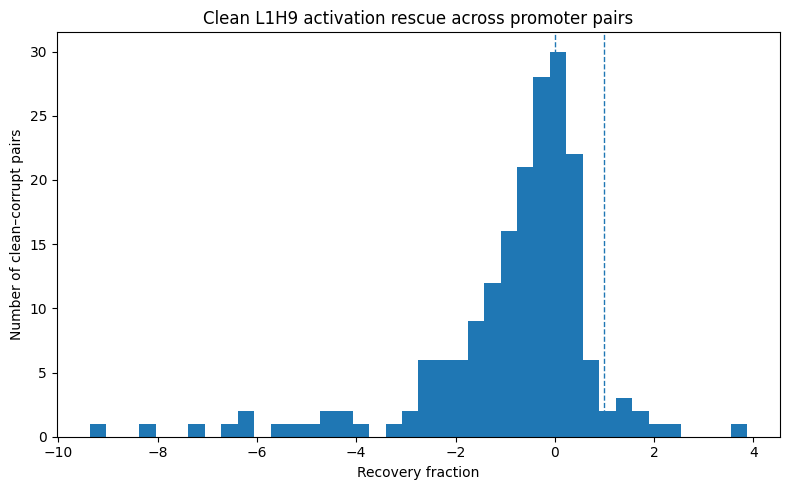


Saved L1H9 patch results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


In [ ]:
L1H9_LAYER_INDEX = 0
L1H9_HEAD_INDEX = 8

l1h9_patch_rows = []

for pair_index in tqdm(
    range(len(rescue_clean_sequences)),
    desc="Patching clean L1H9 into corrupt runs",
):
    clean_sequence = rescue_clean_sequences[pair_index]
    corrupt_sequence = rescue_corrupt_sequences[pair_index]

    projection_matrix = (
        alignment_projection_matrices[pair_index]
    )

    # Cache the clean Layer-1 attention output.
    clean_result = run_single_sequence_and_capture_head(
        clean_sequence,
        layer_index=L1H9_LAYER_INDEX,
    )

    # Patch its L1H9 output into the matched corrupt run.
    patched_result = run_single_sequence_with_head_patch(
        corrupt_sequence=corrupt_sequence,
        layer_index=L1H9_LAYER_INDEX,
        head_index=L1H9_HEAD_INDEX,
        clean_attention_output=(
            clean_result["attention_output"]
        ),
        projection_matrix=projection_matrix,
    )

    clean_logit = rescue_clean_logits[pair_index]
    corrupt_logit = rescue_corrupt_logits[pair_index]
    patched_logit = patched_result["logit"]

    clean_corrupt_gap = clean_logit - corrupt_logit
    rescue_amount = patched_logit - corrupt_logit

    recovery_fraction = (
        rescue_amount / clean_corrupt_gap
    )

    l1h9_patch_rows.append({
        "pair_index": pair_index,
        "original_cohort_index": (
            valid_rescue_indices[pair_index]
        ),
        "clean_logit": clean_logit,
        "corrupt_logit": corrupt_logit,
        "patched_logit": patched_logit,
        "clean_corrupt_gap": clean_corrupt_gap,
        "rescue_amount": rescue_amount,
        "recovery_fraction": recovery_fraction,
        "clean_probability": (
            rescue_clean_probabilities[pair_index]
        ),
        "corrupt_probability": (
            rescue_corrupt_probabilities[pair_index]
        ),
        "patched_probability": (
            patched_result["probability"]
        ),
        "number_patched_tokens": (
            patched_result["number_patched_tokens"]
        ),
        "mean_head_change_norm": (
            patched_result["mean_head_change_norm"]
        ),
    })


l1h9_patch_df = pd.DataFrame(
    l1h9_patch_rows
)

display(l1h9_patch_df.head(10))

l1h9_summary = pd.DataFrame([{
    "component": "L1H9",
    "number_of_pairs": len(l1h9_patch_df),
    "mean_clean_logit": (
        l1h9_patch_df["clean_logit"].mean()
    ),
    "mean_corrupt_logit": (
        l1h9_patch_df["corrupt_logit"].mean()
    ),
    "mean_patched_logit": (
        l1h9_patch_df["patched_logit"].mean()
    ),
    "mean_rescue_amount": (
        l1h9_patch_df["rescue_amount"].mean()
    ),
    "median_rescue_amount": (
        l1h9_patch_df["rescue_amount"].median()
    ),
    "mean_recovery_fraction": (
        l1h9_patch_df["recovery_fraction"].mean()
    ),
    "median_recovery_fraction": (
        l1h9_patch_df["recovery_fraction"].median()
    ),
    "fraction_positive_rescue": (
        l1h9_patch_df["rescue_amount"] > 0
    ).mean(),
    "fraction_at_least_25pct_recovery": (
        l1h9_patch_df["recovery_fraction"] >= 0.25
    ).mean(),
    "fraction_at_least_50pct_recovery": (
        l1h9_patch_df["recovery_fraction"] >= 0.50
    ).mean(),
    "fraction_full_or_over_recovery": (
        l1h9_patch_df["recovery_fraction"] >= 1.0
    ).mean(),
    "fraction_patched_positive": (
        l1h9_patch_df["patched_logit"] > 0
    ).mean(),
}])

print("\nL1H9 cohort summary:")
display(l1h9_summary)

print(
    "\nRecovery-fraction quantiles:"
)

display(
    l1h9_patch_df["recovery_fraction"]
    .quantile(
        [0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .rename("recovery_fraction")
    .reset_index()
    .rename(columns={"index": "quantile"})
)

# Save all pair-level results.
l1h9_patch_df.to_csv(
    CAUSAL_DIR / "l1h9_clean_to_corrupt_patch_results.csv",
    index=False,
)

l1h9_summary.to_csv(
    CAUSAL_DIR / "l1h9_clean_to_corrupt_patch_summary.csv",
    index=False,
)

# Plot the distribution without clipping extreme values.
plt.figure(figsize=(8, 5))

plt.hist(
    l1h9_patch_df["recovery_fraction"],
    bins=40,
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.axvline(
    1,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Recovery fraction")
plt.ylabel("Number of clean–corrupt pairs")
plt.title(
    "Clean L1H9 activation rescue across promoter pairs"
)

plt.tight_layout()

plt.savefig(
    CAUSAL_DIR
    / "l1h9_recovery_fraction_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "\nSaved L1H9 patch results to:",
    CAUSAL_DIR,
)

# Cell 11 — Verify that self-patching reproduces the unpatched corrupt run

In [ ]:
SELF_PATCH_TEST_SIZE = 30

self_patch_rows = []

for pair_index in tqdm(
    range(SELF_PATCH_TEST_SIZE),
    desc="Running corrupt-to-corrupt self-patch control",
):
    corrupt_sequence = rescue_corrupt_sequences[pair_index]

    # Capture the corrupted L1 attention output.
    corrupt_capture = run_single_sequence_and_capture_head(
        corrupt_sequence,
        layer_index=0,
    )

    # Since donor and recipient are identical, their tokenizations
    # and nucleotide spans are identical.
    _, corrupt_offsets = get_token_offsets(
        corrupt_sequence
    )

    identity_span_projection = (
        build_span_projection_matrix(
            clean_offsets=corrupt_offsets,
            corrupt_offsets=corrupt_offsets,
        )
    )

    self_patched_result = (
        run_single_sequence_with_head_patch(
            corrupt_sequence=corrupt_sequence,
            layer_index=0,
            head_index=8,  # L1H9
            clean_attention_output=(
                corrupt_capture["attention_output"]
            ),
            projection_matrix=identity_span_projection,
        )
    )

    baseline_corrupt_logit = (
        rescue_corrupt_logits[pair_index]
    )

    captured_corrupt_logit = (
        corrupt_capture["logit"]
    )

    self_patched_logit = (
        self_patched_result["logit"]
    )

    self_patch_rows.append({
        "pair_index": pair_index,
        "baseline_corrupt_logit": baseline_corrupt_logit,
        "captured_corrupt_logit": captured_corrupt_logit,
        "self_patched_logit": self_patched_logit,
        "capture_difference": (
            captured_corrupt_logit
            - baseline_corrupt_logit
        ),
        "self_patch_difference": (
            self_patched_logit
            - baseline_corrupt_logit
        ),
        "absolute_self_patch_difference": abs(
            self_patched_logit
            - baseline_corrupt_logit
        ),
        "mean_head_change_norm": (
            self_patched_result[
                "mean_head_change_norm"
            ]
        ),
    })


self_patch_control_df = pd.DataFrame(
    self_patch_rows
)

display(self_patch_control_df.head(10))

print(
    "\nMaximum absolute difference after self-patching:",
    self_patch_control_df[
        "absolute_self_patch_difference"
    ].max(),
)

print(
    "Mean absolute difference after self-patching:",
    self_patch_control_df[
        "absolute_self_patch_difference"
    ].mean(),
)

print(
    "Maximum head-change norm:",
    self_patch_control_df[
        "mean_head_change_norm"
    ].max(),
)

SELF_PATCH_TOLERANCE = 1e-4

self_patch_passed = bool(
    self_patch_control_df[
        "absolute_self_patch_difference"
    ].max()
    < SELF_PATCH_TOLERANCE
)

print(
    "\nSelf-patch implementation control passed:",
    self_patch_passed,
)

assert self_patch_passed, (
    "Self-patching changed the model output. "
    "The projection or patching implementation must be fixed "
    "before interpreting clean-to-corrupt rescue."
)

self_patch_control_df.to_csv(
    CAUSAL_DIR / "l1h9_corrupt_self_patch_control.csv",
    index=False,
)

print(
    "\nSaved self-patch control to:",
    CAUSAL_DIR / "l1h9_corrupt_self_patch_control.csv",
)

Running corrupt-to-corrupt self-patch control:   0%|          | 0/30 [00:00<?, ?it/s]

,pair_index,baseline_corrupt_logit,captured_corrupt_logit,self_patched_logit,capture_difference,self_patch_difference,absolute_self_patch_difference,mean_head_change_norm
0,0,3.291286,3.291276,3.291276,-0.000009,-0.000009,0.000009,0.0
1,1,3.685326,3.685322,3.685322,-0.000004,-0.000004,0.000004,0.0
2,2,-0.207787,-0.207781,-0.207781,0.000005,0.000005,0.000005,0.0
3,3,1.402079,1.402066,1.402066,-0.000012,-0.000012,0.000012,0.0
4,4,-7.186104,-7.186094,-7.186094,0.000011,0.000011,0.000011,0.0
5,5,2.551906,2.551902,2.551902,-0.000004,-0.000004,0.000004,0.0
6,6,-8.675502,-8.675513,-8.675513,-0.000011,-0.000011,0.000011,0.0
7,7,13.312646,13.312634,13.312634,-0.000012,-0.000012,0.000012,0.0
8,8,6.511144,6.511128,6.511128,-0.000016,-0.000016,0.000016,0.0
9,9,-2.649134,-2.649145,-2.649145,-0.000011,-0.000011,0.000011,0.0



Maximum absolute difference after self-patching: 2.7812750708733347e-05
Mean absolute difference after self-patching: 1.0072042692921279e-05
Maximum head-change norm: 0.0

Self-patch implementation control passed: True

Saved self-patch control to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/l1h9_corrupt_self_patch_control.csv


# Cell 12 — Compare matched L1H9 donors with unrelated clean donors

In [ ]:
UNRELATED_DONOR_SEED = 123
rng = np.random.default_rng(UNRELATED_DONOR_SEED)

number_of_pairs = len(rescue_clean_sequences)

# Create a derangement-like donor assignment.
# No pair receives its own clean sequence.
unrelated_donor_indices = np.arange(number_of_pairs)

while np.any(
    unrelated_donor_indices == np.arange(number_of_pairs)
):
    unrelated_donor_indices = rng.permutation(
        number_of_pairs
    )


unrelated_patch_rows = []

for recipient_index in tqdm(
    range(number_of_pairs),
    desc="Patching unrelated clean L1H9 donors",
):
    donor_index = unrelated_donor_indices[
        recipient_index
    ]

    donor_clean_sequence = (
        rescue_clean_sequences[donor_index]
    )

    recipient_corrupt_sequence = (
        rescue_corrupt_sequences[recipient_index]
    )

    # Capture L1 attention output from an unrelated clean promoter.
    donor_result = run_single_sequence_and_capture_head(
        donor_clean_sequence,
        layer_index=0,
    )

    # Build projection from donor nucleotide spans to the
    # recipient corrupt nucleotide spans.
    _, donor_offsets = get_token_offsets(
        donor_clean_sequence
    )

    _, recipient_offsets = get_token_offsets(
        recipient_corrupt_sequence
    )

    unrelated_projection = (
        build_span_projection_matrix(
            clean_offsets=donor_offsets,
            corrupt_offsets=recipient_offsets,
        )
    )

    unrelated_patched_result = (
        run_single_sequence_with_head_patch(
            corrupt_sequence=recipient_corrupt_sequence,
            layer_index=0,
            head_index=8,
            clean_attention_output=(
                donor_result["attention_output"]
            ),
            projection_matrix=unrelated_projection,
        )
    )

    corrupt_logit = rescue_corrupt_logits[
        recipient_index
    ]

    unrelated_patched_logit = (
        unrelated_patched_result["logit"]
    )

    unrelated_patch_rows.append({
        "recipient_pair_index": recipient_index,
        "unrelated_donor_index": donor_index,
        "corrupt_logit": corrupt_logit,
        "unrelated_patched_logit": unrelated_patched_logit,
        "unrelated_rescue_amount": (
            unrelated_patched_logit
            - corrupt_logit
        ),
        "unrelated_recovery_fraction": (
            (
                unrelated_patched_logit
                - corrupt_logit
            )
            / rescue_gaps[recipient_index]
        ),
    })


unrelated_patch_df = pd.DataFrame(
    unrelated_patch_rows
)

# Align matched and unrelated results by recipient pair.
matched_vs_unrelated_df = pd.DataFrame({
    "pair_index": np.arange(number_of_pairs),
    "matched_rescue_amount": (
        l1h9_patch_df
        .sort_values("pair_index")[
            "rescue_amount"
        ]
        .to_numpy()
    ),
    "unrelated_rescue_amount": (
        unrelated_patch_df
        .sort_values("recipient_pair_index")[
            "unrelated_rescue_amount"
        ]
        .to_numpy()
    ),
    "matched_recovery_fraction": (
        l1h9_patch_df
        .sort_values("pair_index")[
            "recovery_fraction"
        ]
        .to_numpy()
    ),
    "unrelated_recovery_fraction": (
        unrelated_patch_df
        .sort_values("recipient_pair_index")[
            "unrelated_recovery_fraction"
        ]
        .to_numpy()
    ),
})

matched_vs_unrelated_df[
    "matched_minus_unrelated_rescue"
] = (
    matched_vs_unrelated_df[
        "matched_rescue_amount"
    ]
    - matched_vs_unrelated_df[
        "unrelated_rescue_amount"
    ]
)

display(matched_vs_unrelated_df.head(10))

print("\nMatched donor mean rescue:")
print(
    matched_vs_unrelated_df[
        "matched_rescue_amount"
    ].mean()
)

print("\nUnrelated donor mean rescue:")
print(
    matched_vs_unrelated_df[
        "unrelated_rescue_amount"
    ].mean()
)

print("\nMatched minus unrelated mean:")
print(
    matched_vs_unrelated_df[
        "matched_minus_unrelated_rescue"
    ].mean()
)

print("\nFraction matched better than unrelated:")
print(
    (
        matched_vs_unrelated_df[
            "matched_minus_unrelated_rescue"
        ] > 0
    ).mean()
)

matched_vs_unrelated_df.to_csv(
    CAUSAL_DIR
    / "l1h9_matched_vs_unrelated_donor_results.csv",
    index=False,
)

print(
    "\nSaved matched-versus-unrelated control to:",
    CAUSAL_DIR
    / "l1h9_matched_vs_unrelated_donor_results.csv",
)

Patching unrelated clean L1H9 donors:   0%|          | 0/189 [00:00<?, ?it/s]

,pair_index,matched_rescue_amount,unrelated_rescue_amount,matched_recovery_fraction,unrelated_recovery_fraction,matched_minus_unrelated_rescue
0,0,4.413462,2.799039,2.099342,1.331413,1.614423
1,1,0.117973,4.562996,0.089231,3.451318,-4.445023
2,2,-1.428585,8.125903,-0.219859,1.250576,-9.554488
3,3,-0.434366,-7.753551,-0.154598,-2.759619,7.319185
4,4,-0.837776,6.252609,-0.087107,0.650107,-7.090385
5,5,-3.477420,-5.913713,-0.961145,-1.634527,2.436293
6,6,0.467351,0.908349,0.023952,0.046553,-0.440998
7,7,-1.277034,3.380178,-0.156205,0.413458,-4.657212
8,8,16.880699,-3.716367,1.603842,-0.353094,20.597067
9,9,3.823518,4.077614,0.332167,0.354242,-0.254096



Matched donor mean rescue:
-2.3840565172947477

Unrelated donor mean rescue:
-2.919634512171763

Matched minus unrelated mean:
0.5355779948770153

Fraction matched better than unrelated:
0.5502645502645502

Saved matched-versus-unrelated control to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/l1h9_matched_vs_unrelated_donor_results.csv


# Cell 13 — Paired uncertainty test for matched versus unrelated donors

In [ ]:
N_BOOTSTRAPS = 5000
bootstrap_rng = np.random.default_rng(SEED)

matched_effects = (
    matched_vs_unrelated_df[
        "matched_rescue_amount"
    ].to_numpy()
)

unrelated_effects = (
    matched_vs_unrelated_df[
        "unrelated_rescue_amount"
    ].to_numpy()
)

paired_difference = (
    matched_effects
    - unrelated_effects
)

bootstrap_means = np.empty(N_BOOTSTRAPS)

for bootstrap_index in range(N_BOOTSTRAPS):
    sampled_indices = bootstrap_rng.integers(
        0,
        len(paired_difference),
        size=len(paired_difference),
    )

    bootstrap_means[bootstrap_index] = (
        paired_difference[
            sampled_indices
        ].mean()
    )


matched_donor_control_summary = pd.DataFrame([{
    "comparison": "matched minus unrelated L1H9 donor",
    "number_of_pairs": len(paired_difference),
    "matched_mean_rescue": matched_effects.mean(),
    "unrelated_mean_rescue": unrelated_effects.mean(),
    "mean_paired_difference": paired_difference.mean(),
    "median_paired_difference": np.median(
        paired_difference
    ),
    "ci_2.5": np.percentile(
        bootstrap_means,
        2.5,
    ),
    "ci_97.5": np.percentile(
        bootstrap_means,
        97.5,
    ),
    "fraction_matched_better": np.mean(
        paired_difference > 0
    ),
}])

display(matched_donor_control_summary)

lower_ci = matched_donor_control_summary[
    "ci_2.5"
].iloc[0]

upper_ci = matched_donor_control_summary[
    "ci_97.5"
].iloc[0]

if lower_ci > 0:
    conclusion = (
        "Matched donors reliably outperform "
        "unrelated donors."
    )
elif upper_ci < 0:
    conclusion = (
        "Matched donors reliably underperform "
        "unrelated donors."
    )
else:
    conclusion = (
        "The matched-versus-unrelated donor "
        "difference is statistically uncertain."
    )

print("\nConclusion:", conclusion)

# Also test whether absolute matched rescue is positive.
matched_rescue_bootstrap_means = np.empty(
    N_BOOTSTRAPS
)

for bootstrap_index in range(N_BOOTSTRAPS):
    sampled_indices = bootstrap_rng.integers(
        0,
        len(matched_effects),
        size=len(matched_effects),
    )

    matched_rescue_bootstrap_means[
        bootstrap_index
    ] = matched_effects[
        sampled_indices
    ].mean()


absolute_rescue_summary = pd.DataFrame([{
    "component": "L1H9 matched clean patch",
    "mean_rescue": matched_effects.mean(),
    "ci_2.5": np.percentile(
        matched_rescue_bootstrap_means,
        2.5,
    ),
    "ci_97.5": np.percentile(
        matched_rescue_bootstrap_means,
        97.5,
    ),
    "fraction_positive_rescue": np.mean(
        matched_effects > 0
    ),
}])

print("\nAbsolute matched-donor rescue:")
display(absolute_rescue_summary)

matched_donor_control_summary.to_csv(
    CAUSAL_DIR
    / "l1h9_matched_vs_unrelated_bootstrap_summary.csv",
    index=False,
)

absolute_rescue_summary.to_csv(
    CAUSAL_DIR
    / "l1h9_absolute_rescue_bootstrap_summary.csv",
    index=False,
)

print(
    "\nSaved bootstrap controls to:",
    CAUSAL_DIR,
)

,comparison,number_of_pairs,matched_mean_rescue,unrelated_mean_rescue,mean_paired_difference,median_paired_difference,ci_2.5,ci_97.5,fraction_matched_better
0,matched minus unrelated L1H9 donor,189,-2.384057,-2.919635,0.535578,0.93981,-0.578686,1.696984,0.550265



Conclusion: The matched-versus-unrelated donor difference is statistically uncertain.

Absolute matched-donor rescue:


,component,mean_rescue,ci_2.5,ci_97.5,fraction_positive_rescue
0,L1H9 matched clean patch,-2.384057,-3.139282,-1.595806,0.312169



Saved bootstrap controls to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


# Cell 14 — Smoke-test full Layer-1 attention clean-to-corrupt patching

In [ ]:
BRANCH_LAYER_INDEX = 0
BRANCH_TYPE = "attention"


def get_branch_module(layer_index, branch_type):
    if branch_type == "attention":
        return (
            backbone.encoder.layer[layer_index]
            .attention.output.dense
        )

    if branch_type == "mlp":
        return (
            backbone.encoder.layer[layer_index]
            .mlp.wo
        )

    raise ValueError(
        f"Unknown branch type: {branch_type}"
    )


def run_single_sequence_and_capture_branch(
    sequence,
    layer_index,
    branch_type,
):
    """
    Capture the selected branch output and score the
    resulting Layer-5 representation.
    """
    branch_module = get_branch_module(
        layer_index,
        branch_type,
    )

    captured_branch = {}

    def capture_branch_output(module, inputs, output):
        if not torch.is_tensor(output):
            raise TypeError(
                f"Expected tensor output, got {type(output)}"
            )

        captured_branch["value"] = (
            output.detach().clone()
        )

    branch_handle = branch_module.register_forward_hook(
        capture_branch_output
    )

    try:
        encoded = tokenizer(
            sequence,
            return_tensors="pt",
            padding=False,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_count = int(
            encoded["attention_mask"].sum().item()
        )

        captured_layers.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        branch_output = captured_branch["value"]

        if branch_output.shape[0] != token_count:
            raise RuntimeError(
                "Captured branch-token count does not "
                "match the tokenizer token count."
            )

        pooled_layer5 = split_and_content_mean_pool(
            captured_layers[LAYER5_INDEX],
            [token_count],
        )

        representation = (
            pooled_layer5.cpu().numpy()
        )

        return {
            "branch_output": branch_output.cpu(),
            "layer5_representation": representation[0],
            "logit": float(
                layer5_probe.decision_function(
                    representation
                )[0]
            ),
            "probability": float(
                layer5_probe.predict_proba(
                    representation
                )[0, 1]
            ),
            "token_count": token_count,
        }

    finally:
        branch_handle.remove()


def run_single_sequence_with_branch_patch(
    corrupt_sequence,
    layer_index,
    branch_type,
    clean_branch_output,
    projection_matrix,
):
    """
    Replace all content-token outputs of one branch with
    nucleotide-span-projected clean outputs.
    """
    branch_module = get_branch_module(
        layer_index,
        branch_type,
    )

    diagnostics = {}

    def patch_branch_output(module, inputs, output):
        if not torch.is_tensor(output):
            raise TypeError(
                f"Expected tensor output, got {type(output)}"
            )

        corrupt_token_count = output.shape[0]
        clean_token_count = clean_branch_output.shape[0]

        if projection_matrix.shape != (
            corrupt_token_count,
            clean_token_count,
        ):
            raise ValueError(
                "Projection shape does not match clean and "
                "corrupt branch-output token counts."
            )

        projection = projection_matrix.to(
            device=output.device,
            dtype=output.dtype,
        )

        clean_output = clean_branch_output.to(
            device=output.device,
            dtype=output.dtype,
        )

        projected_clean_output = (
            projection @ clean_output
        )

        content_row_mask = (
            projection.sum(dim=1) > 0
        )

        patched_output = output.clone()

        original_content_output = (
            patched_output[content_row_mask]
            .detach()
            .clone()
        )

        patched_output[
            content_row_mask
        ] = projected_clean_output[
            content_row_mask
        ]

        diagnostics["number_patched_tokens"] = int(
            content_row_mask.sum().item()
        )

        diagnostics["mean_branch_change_norm"] = float(
            torch.linalg.vector_norm(
                patched_output[content_row_mask]
                - original_content_output,
                dim=1,
            )
            .mean()
            .item()
        )

        return patched_output

    patch_handle = branch_module.register_forward_hook(
        patch_branch_output
    )

    try:
        encoded = tokenizer(
            corrupt_sequence,
            return_tensors="pt",
            padding=False,
            truncation=True,
            max_length=128,
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        token_count = int(
            encoded["attention_mask"].sum().item()
        )

        captured_layers.clear()

        with torch.no_grad():
            _ = backbone(
                **encoded,
                return_dict=False,
            )

        pooled_layer5 = split_and_content_mean_pool(
            captured_layers[LAYER5_INDEX],
            [token_count],
        )

        representation = (
            pooled_layer5.cpu().numpy()
        )

        return {
            "layer5_representation": representation[0],
            "logit": float(
                layer5_probe.decision_function(
                    representation
                )[0]
            ),
            "probability": float(
                layer5_probe.predict_proba(
                    representation
                )[0, 1]
            ),
            "token_count": token_count,
            **diagnostics,
        }

    finally:
        patch_handle.remove()


# Smoke-test the same first rescue pair.
branch_smoke_pair_index = 0

branch_clean_result = (
    run_single_sequence_and_capture_branch(
        rescue_clean_sequences[
            branch_smoke_pair_index
        ],
        layer_index=BRANCH_LAYER_INDEX,
        branch_type=BRANCH_TYPE,
    )
)

branch_corrupt_result = (
    run_single_sequence_and_capture_branch(
        rescue_corrupt_sequences[
            branch_smoke_pair_index
        ],
        layer_index=BRANCH_LAYER_INDEX,
        branch_type=BRANCH_TYPE,
    )
)

branch_patched_result = (
    run_single_sequence_with_branch_patch(
        corrupt_sequence=(
            rescue_corrupt_sequences[
                branch_smoke_pair_index
            ]
        ),
        layer_index=BRANCH_LAYER_INDEX,
        branch_type=BRANCH_TYPE,
        clean_branch_output=(
            branch_clean_result["branch_output"]
        ),
        projection_matrix=(
            alignment_projection_matrices[
                branch_smoke_pair_index
            ]
        ),
    )
)

branch_clean_logit = branch_clean_result["logit"]
branch_corrupt_logit = branch_corrupt_result["logit"]
branch_patched_logit = branch_patched_result["logit"]

branch_gap = (
    branch_clean_logit
    - branch_corrupt_logit
)

branch_rescue_amount = (
    branch_patched_logit
    - branch_corrupt_logit
)

branch_recovery_fraction = (
    branch_rescue_amount
    / branch_gap
)

branch_smoke_summary = pd.DataFrame([
    {
        "condition": "clean",
        "logit": branch_clean_logit,
        "probability": (
            branch_clean_result["probability"]
        ),
    },
    {
        "condition": "dinucleotide corrupt",
        "logit": branch_corrupt_logit,
        "probability": (
            branch_corrupt_result["probability"]
        ),
    },
    {
        "condition": (
            "corrupt + clean Layer-1 attention patch"
        ),
        "logit": branch_patched_logit,
        "probability": (
            branch_patched_result["probability"]
        ),
    },
])

display(branch_smoke_summary)

print("\nClean-corrupt gap:", branch_gap)
print("Branch rescue amount:", branch_rescue_amount)
print(
    "Branch recovery fraction:",
    branch_recovery_fraction,
)
print(
    "Patched content tokens:",
    branch_patched_result[
        "number_patched_tokens"
    ],
)
print(
    "Mean branch change norm:",
    branch_patched_result[
        "mean_branch_change_norm"
    ],
)

assert np.isfinite(branch_recovery_fraction)

assert (
    branch_patched_result["number_patched_tokens"]
    == branch_corrupt_result["token_count"] - 2
)

print(
    "\nLayer-1 attention branch patch "
    "smoke test passed."
)

,condition,logit,probability
0,clean,5.393570,0.995475
1,dinucleotide corrupt,3.291276,0.964128
2,corrupt + clean Layer-1 attention patch,8.435811,0.999783



Clean-corrupt gap: 2.1022938401477695
Branch rescue amount: 5.144534401847737
Branch recovery fraction: 2.4471053016480937
Patched content tokens: 17
Mean branch change norm: 2.7477900981903076

Layer-1 attention branch patch smoke test passed.


# Cell 15 — Full-cohort Layer-1 attention branch patching

Patching clean Layer-1 attention into corrupt runs:   0%|          | 0/189 [00:00<?, ?it/s]

,pair_index,original_cohort_index,clean_logit,corrupt_logit,patched_logit,clean_corrupt_gap,rescue_amount,recovery_fraction,clean_probability,corrupt_probability,patched_probability,number_patched_tokens,mean_branch_change_norm
0,0,0,5.393593,3.291286,8.435811,2.102307,5.144525,2.447085,0.995475,0.964129,0.999783,17,2.747790
1,1,1,5.007429,3.685326,3.103471,1.322102,-0.581856,-0.440099,0.993356,0.975525,0.957036,16,3.178554
2,2,2,6.289941,-0.207787,1.138620,6.497728,1.346406,0.207212,0.998149,0.448239,0.757426,15,3.115593
3,3,3,4.211724,1.402079,2.141172,2.809645,0.739093,0.263056,0.985396,0.802514,0.894841,16,3.047254
4,4,6,2.431718,-7.186104,-5.820509,9.617822,1.365595,0.141986,0.919214,0.000756,0.002957,15,2.858827
5,5,7,6.169904,2.551906,3.761973,3.617998,1.210067,0.334458,0.997913,0.927701,0.977290,16,2.912667
6,6,8,10.836474,-8.675502,-11.872060,19.511976,-3.196558,-0.163825,0.999980,0.000171,0.000007,16,2.903455
7,7,9,21.488038,13.312646,11.983514,8.175392,-1.329131,-0.162577,1.000000,0.999998,0.999994,15,2.822266
8,8,11,17.036306,6.511144,15.092276,10.525162,8.581132,0.815297,1.000000,0.998515,1.000000,17,3.072048
9,9,13,8.861694,-2.649134,0.177137,11.510828,2.826270,0.245531,0.999858,0.066042,0.544169,14,3.699205



Layer-1 attention patch summary:


,component,number_of_pairs,mean_clean_logit,mean_corrupt_logit,mean_patched_logit,mean_rescue_amount,median_rescue_amount,mean_recovery_fraction,median_recovery_fraction,fraction_positive_rescue,fraction_at_least_25pct_recovery,fraction_at_least_50pct_recovery,fraction_full_or_over_recovery,fraction_patched_positive
0,Layer 1 attention branch,189,7.393424,1.024347,0.218538,-0.805809,-1.043473,-0.395322,-0.162577,0.386243,0.227513,0.142857,0.063492,0.52381



Recovery-fraction quantiles:


,quantile,recovery_fraction
0,0.05,-2.541334
1,0.25,-0.624939
2,0.50,-0.162577
3,0.75,0.223742
4,0.95,1.034905



Bootstrap absolute-rescue summary:


,component,mean_rescue,ci_2.5,ci_97.5,fraction_positive_rescue
0,Layer 1 attention branch,-0.805809,-1.363113,-0.248188,0.386243


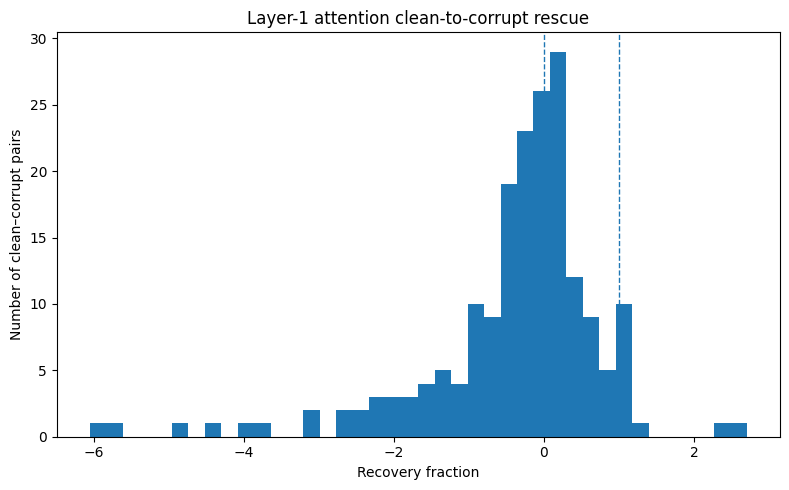


Saved Layer-1 attention patch results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


In [ ]:
layer1_attention_patch_rows = []

for pair_index in tqdm(
    range(len(rescue_clean_sequences)),
    desc="Patching clean Layer-1 attention into corrupt runs",
):
    clean_sequence = rescue_clean_sequences[pair_index]
    corrupt_sequence = rescue_corrupt_sequences[pair_index]

    projection_matrix = (
        alignment_projection_matrices[pair_index]
    )

    clean_result = (
        run_single_sequence_and_capture_branch(
            clean_sequence,
            layer_index=0,
            branch_type="attention",
        )
    )

    patched_result = (
        run_single_sequence_with_branch_patch(
            corrupt_sequence=corrupt_sequence,
            layer_index=0,
            branch_type="attention",
            clean_branch_output=(
                clean_result["branch_output"]
            ),
            projection_matrix=projection_matrix,
        )
    )

    clean_logit = rescue_clean_logits[pair_index]
    corrupt_logit = rescue_corrupt_logits[pair_index]
    patched_logit = patched_result["logit"]

    clean_corrupt_gap = (
        clean_logit - corrupt_logit
    )

    rescue_amount = (
        patched_logit - corrupt_logit
    )

    recovery_fraction = (
        rescue_amount / clean_corrupt_gap
    )

    layer1_attention_patch_rows.append({
        "pair_index": pair_index,
        "original_cohort_index": (
            valid_rescue_indices[pair_index]
        ),
        "clean_logit": clean_logit,
        "corrupt_logit": corrupt_logit,
        "patched_logit": patched_logit,
        "clean_corrupt_gap": clean_corrupt_gap,
        "rescue_amount": rescue_amount,
        "recovery_fraction": recovery_fraction,
        "clean_probability": (
            rescue_clean_probabilities[pair_index]
        ),
        "corrupt_probability": (
            rescue_corrupt_probabilities[pair_index]
        ),
        "patched_probability": (
            patched_result["probability"]
        ),
        "number_patched_tokens": (
            patched_result["number_patched_tokens"]
        ),
        "mean_branch_change_norm": (
            patched_result["mean_branch_change_norm"]
        ),
    })


layer1_attention_patch_df = pd.DataFrame(
    layer1_attention_patch_rows
)

display(layer1_attention_patch_df.head(10))

layer1_attention_summary = pd.DataFrame([{
    "component": "Layer 1 attention branch",
    "number_of_pairs": (
        len(layer1_attention_patch_df)
    ),
    "mean_clean_logit": (
        layer1_attention_patch_df[
            "clean_logit"
        ].mean()
    ),
    "mean_corrupt_logit": (
        layer1_attention_patch_df[
            "corrupt_logit"
        ].mean()
    ),
    "mean_patched_logit": (
        layer1_attention_patch_df[
            "patched_logit"
        ].mean()
    ),
    "mean_rescue_amount": (
        layer1_attention_patch_df[
            "rescue_amount"
        ].mean()
    ),
    "median_rescue_amount": (
        layer1_attention_patch_df[
            "rescue_amount"
        ].median()
    ),
    "mean_recovery_fraction": (
        layer1_attention_patch_df[
            "recovery_fraction"
        ].mean()
    ),
    "median_recovery_fraction": (
        layer1_attention_patch_df[
            "recovery_fraction"
        ].median()
    ),
    "fraction_positive_rescue": (
        layer1_attention_patch_df[
            "rescue_amount"
        ] > 0
    ).mean(),
    "fraction_at_least_25pct_recovery": (
        layer1_attention_patch_df[
            "recovery_fraction"
        ] >= 0.25
    ).mean(),
    "fraction_at_least_50pct_recovery": (
        layer1_attention_patch_df[
            "recovery_fraction"
        ] >= 0.50
    ).mean(),
    "fraction_full_or_over_recovery": (
        layer1_attention_patch_df[
            "recovery_fraction"
        ] >= 1.0
    ).mean(),
    "fraction_patched_positive": (
        layer1_attention_patch_df[
            "patched_logit"
        ] > 0
    ).mean(),
}])

print("\nLayer-1 attention patch summary:")
display(layer1_attention_summary)

print("\nRecovery-fraction quantiles:")

display(
    layer1_attention_patch_df[
        "recovery_fraction"
    ]
    .quantile(
        [0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .rename("recovery_fraction")
    .reset_index()
    .rename(columns={"index": "quantile"})
)

# Paired bootstrap for mean absolute rescue.
N_BOOTSTRAPS = 5000
bootstrap_rng = np.random.default_rng(SEED)

branch_rescue_values = (
    layer1_attention_patch_df[
        "rescue_amount"
    ].to_numpy()
)

bootstrap_mean_rescue = np.empty(
    N_BOOTSTRAPS
)

for bootstrap_index in range(N_BOOTSTRAPS):
    sampled_indices = bootstrap_rng.integers(
        0,
        len(branch_rescue_values),
        size=len(branch_rescue_values),
    )

    bootstrap_mean_rescue[
        bootstrap_index
    ] = branch_rescue_values[
        sampled_indices
    ].mean()


layer1_attention_bootstrap_summary = pd.DataFrame([{
    "component": "Layer 1 attention branch",
    "mean_rescue": branch_rescue_values.mean(),
    "ci_2.5": np.percentile(
        bootstrap_mean_rescue,
        2.5,
    ),
    "ci_97.5": np.percentile(
        bootstrap_mean_rescue,
        97.5,
    ),
    "fraction_positive_rescue": np.mean(
        branch_rescue_values > 0
    ),
}])

print("\nBootstrap absolute-rescue summary:")
display(layer1_attention_bootstrap_summary)

layer1_attention_patch_df.to_csv(
    CAUSAL_DIR
    / "layer1_attention_clean_to_corrupt_patch_results.csv",
    index=False,
)

layer1_attention_summary.to_csv(
    CAUSAL_DIR
    / "layer1_attention_clean_to_corrupt_patch_summary.csv",
    index=False,
)

layer1_attention_bootstrap_summary.to_csv(
    CAUSAL_DIR
    / "layer1_attention_patch_bootstrap_summary.csv",
    index=False,
)

plt.figure(figsize=(8, 5))

plt.hist(
    layer1_attention_patch_df[
        "recovery_fraction"
    ],
    bins=40,
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.axvline(
    1,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Recovery fraction")
plt.ylabel("Number of clean–corrupt pairs")
plt.title(
    "Layer-1 attention clean-to-corrupt rescue"
)

plt.tight_layout()

plt.savefig(
    CAUSAL_DIR
    / "layer1_attention_recovery_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "\nSaved Layer-1 attention patch results to:",
    CAUSAL_DIR,
)

# Cell 16 — full-cohort Layer-1 MLP patching

Patching clean Layer-1 MLP into corrupt runs:   0%|          | 0/189 [00:00<?, ?it/s]

,pair_index,original_cohort_index,clean_logit,corrupt_logit,patched_logit,clean_corrupt_gap,rescue_amount,recovery_fraction,clean_probability,corrupt_probability,patched_probability,number_patched_tokens,mean_branch_change_norm
0,0,0,5.393593,3.291286,15.882041,2.102307,12.590756,5.989018,0.995475,0.964129,1.000000,17,3.912835
1,1,1,5.007429,3.685326,16.780616,1.322102,13.095290,9.904899,0.993356,0.975525,1.000000,16,4.165058
2,2,2,6.289941,-0.207787,25.730549,6.497728,25.938336,3.991909,0.998149,0.448239,1.000000,15,3.823314
3,3,3,4.211724,1.402079,12.576842,2.809645,11.174763,3.977286,0.985396,0.802514,0.999997,16,4.107849
4,4,6,2.431718,-7.186104,6.233569,9.617822,13.419673,1.395292,0.919214,0.000756,0.998041,15,4.307141
5,5,7,6.169904,2.551906,8.795226,3.617998,6.243320,1.725629,0.997913,0.927701,0.999849,16,3.730744
6,6,8,10.836474,-8.675502,6.490714,19.511976,15.166216,0.777277,0.999980,0.000171,0.998485,16,4.162109
7,7,9,21.488038,13.312646,23.786960,8.175392,10.474314,1.281200,1.000000,0.999998,1.000000,15,3.678192
8,8,11,17.036306,6.511144,37.103267,10.525162,30.592123,2.906570,1.000000,0.998515,1.000000,17,4.086427
9,9,13,8.861694,-2.649134,14.487818,11.510828,17.136952,1.488768,0.999858,0.066042,0.999999,14,4.150412



Layer-1 MLP patch summary:


,component,number_of_pairs,mean_clean_logit,mean_corrupt_logit,mean_patched_logit,mean_rescue_amount,median_rescue_amount,mean_recovery_fraction,median_recovery_fraction,fraction_positive_rescue,fraction_at_least_25pct_recovery,fraction_at_least_50pct_recovery,fraction_full_or_over_recovery,fraction_patched_positive
0,Layer 1 MLP branch,189,7.393424,1.024347,11.833925,10.809579,10.496404,2.36726,1.730659,0.899471,0.878307,0.835979,0.730159,0.904762



Recovery-fraction quantiles:


,quantile,recovery_fraction
0,0.05,-0.495019
1,0.25,0.888804
2,0.50,1.730659
3,0.75,3.224838
4,0.95,6.572337



Bootstrap absolute-rescue summary:


,component,mean_rescue,ci_2.5,ci_97.5,fraction_positive_rescue
0,Layer 1 MLP branch,10.809579,9.601774,12.009045,0.899471


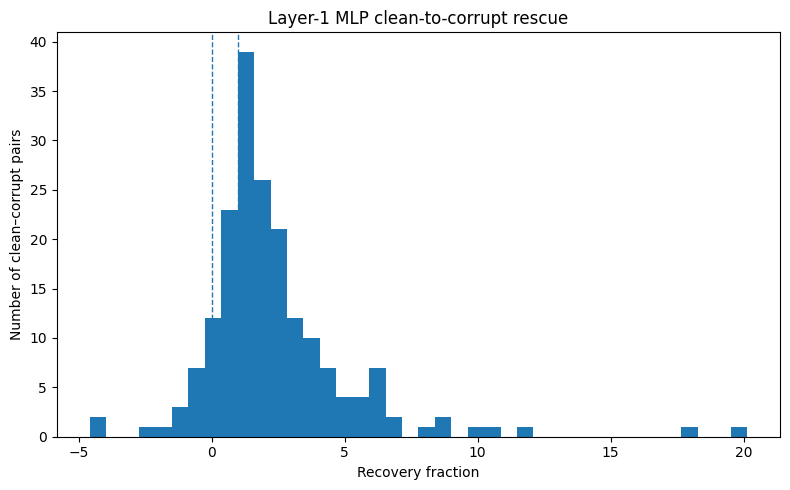


Saved Layer-1 MLP patch results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


In [ ]:
layer1_mlp_patch_rows = []

for pair_index in tqdm(
    range(len(rescue_clean_sequences)),
    desc="Patching clean Layer-1 MLP into corrupt runs",
):
    clean_sequence = rescue_clean_sequences[pair_index]
    corrupt_sequence = rescue_corrupt_sequences[pair_index]

    projection_matrix = (
        alignment_projection_matrices[pair_index]
    )

    clean_result = (
        run_single_sequence_and_capture_branch(
            clean_sequence,
            layer_index=0,
            branch_type="mlp",
        )
    )

    patched_result = (
        run_single_sequence_with_branch_patch(
            corrupt_sequence=corrupt_sequence,
            layer_index=0,
            branch_type="mlp",
            clean_branch_output=(
                clean_result["branch_output"]
            ),
            projection_matrix=projection_matrix,
        )
    )

    clean_logit = rescue_clean_logits[pair_index]
    corrupt_logit = rescue_corrupt_logits[pair_index]
    patched_logit = patched_result["logit"]

    clean_corrupt_gap = (
        clean_logit - corrupt_logit
    )

    rescue_amount = (
        patched_logit - corrupt_logit
    )

    recovery_fraction = (
        rescue_amount / clean_corrupt_gap
    )

    layer1_mlp_patch_rows.append({
        "pair_index": pair_index,
        "original_cohort_index": (
            valid_rescue_indices[pair_index]
        ),
        "clean_logit": clean_logit,
        "corrupt_logit": corrupt_logit,
        "patched_logit": patched_logit,
        "clean_corrupt_gap": clean_corrupt_gap,
        "rescue_amount": rescue_amount,
        "recovery_fraction": recovery_fraction,
        "clean_probability": (
            rescue_clean_probabilities[pair_index]
        ),
        "corrupt_probability": (
            rescue_corrupt_probabilities[pair_index]
        ),
        "patched_probability": (
            patched_result["probability"]
        ),
        "number_patched_tokens": (
            patched_result["number_patched_tokens"]
        ),
        "mean_branch_change_norm": (
            patched_result["mean_branch_change_norm"]
        ),
    })


layer1_mlp_patch_df = pd.DataFrame(
    layer1_mlp_patch_rows
)

display(layer1_mlp_patch_df.head(10))

layer1_mlp_summary = pd.DataFrame([{
    "component": "Layer 1 MLP branch",
    "number_of_pairs": len(layer1_mlp_patch_df),
    "mean_clean_logit": (
        layer1_mlp_patch_df["clean_logit"].mean()
    ),
    "mean_corrupt_logit": (
        layer1_mlp_patch_df["corrupt_logit"].mean()
    ),
    "mean_patched_logit": (
        layer1_mlp_patch_df["patched_logit"].mean()
    ),
    "mean_rescue_amount": (
        layer1_mlp_patch_df["rescue_amount"].mean()
    ),
    "median_rescue_amount": (
        layer1_mlp_patch_df["rescue_amount"].median()
    ),
    "mean_recovery_fraction": (
        layer1_mlp_patch_df[
            "recovery_fraction"
        ].mean()
    ),
    "median_recovery_fraction": (
        layer1_mlp_patch_df[
            "recovery_fraction"
        ].median()
    ),
    "fraction_positive_rescue": (
        layer1_mlp_patch_df["rescue_amount"] > 0
    ).mean(),
    "fraction_at_least_25pct_recovery": (
        layer1_mlp_patch_df[
            "recovery_fraction"
        ] >= 0.25
    ).mean(),
    "fraction_at_least_50pct_recovery": (
        layer1_mlp_patch_df[
            "recovery_fraction"
        ] >= 0.50
    ).mean(),
    "fraction_full_or_over_recovery": (
        layer1_mlp_patch_df[
            "recovery_fraction"
        ] >= 1.0
    ).mean(),
    "fraction_patched_positive": (
        layer1_mlp_patch_df["patched_logit"] > 0
    ).mean(),
}])

print("\nLayer-1 MLP patch summary:")
display(layer1_mlp_summary)

print("\nRecovery-fraction quantiles:")

display(
    layer1_mlp_patch_df[
        "recovery_fraction"
    ]
    .quantile(
        [0.05, 0.25, 0.50, 0.75, 0.95]
    )
    .rename("recovery_fraction")
    .reset_index()
    .rename(columns={"index": "quantile"})
)

# Bootstrap uncertainty for mean rescue.
N_BOOTSTRAPS = 5000
bootstrap_rng = np.random.default_rng(SEED)

mlp_rescue_values = (
    layer1_mlp_patch_df[
        "rescue_amount"
    ].to_numpy()
)

bootstrap_mean_rescue = np.empty(
    N_BOOTSTRAPS
)

for bootstrap_index in range(N_BOOTSTRAPS):
    sampled_indices = bootstrap_rng.integers(
        0,
        len(mlp_rescue_values),
        size=len(mlp_rescue_values),
    )

    bootstrap_mean_rescue[
        bootstrap_index
    ] = mlp_rescue_values[
        sampled_indices
    ].mean()


layer1_mlp_bootstrap_summary = pd.DataFrame([{
    "component": "Layer 1 MLP branch",
    "mean_rescue": mlp_rescue_values.mean(),
    "ci_2.5": np.percentile(
        bootstrap_mean_rescue,
        2.5,
    ),
    "ci_97.5": np.percentile(
        bootstrap_mean_rescue,
        97.5,
    ),
    "fraction_positive_rescue": np.mean(
        mlp_rescue_values > 0
    ),
}])

print("\nBootstrap absolute-rescue summary:")
display(layer1_mlp_bootstrap_summary)

layer1_mlp_patch_df.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_clean_to_corrupt_patch_results.csv",
    index=False,
)

layer1_mlp_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_clean_to_corrupt_patch_summary.csv",
    index=False,
)

layer1_mlp_bootstrap_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_patch_bootstrap_summary.csv",
    index=False,
)

plt.figure(figsize=(8, 5))

plt.hist(
    layer1_mlp_patch_df[
        "recovery_fraction"
    ],
    bins=40,
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.axvline(
    1,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Recovery fraction")
plt.ylabel("Number of clean–corrupt pairs")
plt.title(
    "Layer-1 MLP clean-to-corrupt rescue"
)

plt.tight_layout()

plt.savefig(
    CAUSAL_DIR
    / "layer1_mlp_recovery_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "\nSaved Layer-1 MLP patch results to:",
    CAUSAL_DIR,
)

# Cell 17 — Verify that Layer-1 MLP self-patching is neutral

In [ ]:
MLP_SELF_PATCH_TEST_SIZE = 30

mlp_self_patch_rows = []

for pair_index in tqdm(
    range(MLP_SELF_PATCH_TEST_SIZE),
    desc="Running Layer-1 MLP corrupt self-patch control",
):
    corrupt_sequence = rescue_corrupt_sequences[
        pair_index
    ]

    # Capture the corrupted Layer-1 MLP output.
    corrupt_capture = (
        run_single_sequence_and_capture_branch(
            corrupt_sequence,
            layer_index=0,
            branch_type="mlp",
        )
    )

    _, corrupt_offsets = get_token_offsets(
        corrupt_sequence
    )

    identity_projection = (
        build_span_projection_matrix(
            clean_offsets=corrupt_offsets,
            corrupt_offsets=corrupt_offsets,
        )
    )

    self_patched_result = (
        run_single_sequence_with_branch_patch(
            corrupt_sequence=corrupt_sequence,
            layer_index=0,
            branch_type="mlp",
            clean_branch_output=(
                corrupt_capture["branch_output"]
            ),
            projection_matrix=identity_projection,
        )
    )

    baseline_logit = rescue_corrupt_logits[
        pair_index
    ]

    captured_logit = corrupt_capture["logit"]

    self_patched_logit = (
        self_patched_result["logit"]
    )

    mlp_self_patch_rows.append({
        "pair_index": pair_index,
        "baseline_corrupt_logit": baseline_logit,
        "captured_corrupt_logit": captured_logit,
        "self_patched_logit": self_patched_logit,
        "capture_difference": (
            captured_logit - baseline_logit
        ),
        "self_patch_difference": (
            self_patched_logit - baseline_logit
        ),
        "absolute_self_patch_difference": abs(
            self_patched_logit - baseline_logit
        ),
        "mean_branch_change_norm": (
            self_patched_result[
                "mean_branch_change_norm"
            ]
        ),
    })


mlp_self_patch_control_df = pd.DataFrame(
    mlp_self_patch_rows
)

display(mlp_self_patch_control_df.head(10))

print(
    "\nMaximum absolute self-patch difference:",
    mlp_self_patch_control_df[
        "absolute_self_patch_difference"
    ].max(),
)

print(
    "Mean absolute self-patch difference:",
    mlp_self_patch_control_df[
        "absolute_self_patch_difference"
    ].mean(),
)

print(
    "Maximum branch-change norm:",
    mlp_self_patch_control_df[
        "mean_branch_change_norm"
    ].max(),
)

MLP_SELF_PATCH_TOLERANCE = 1e-4

mlp_self_patch_passed = bool(
    mlp_self_patch_control_df[
        "absolute_self_patch_difference"
    ].max()
    < MLP_SELF_PATCH_TOLERANCE
)

print(
    "\nLayer-1 MLP self-patch control passed:",
    mlp_self_patch_passed,
)

assert mlp_self_patch_passed, (
    "Layer-1 MLP self-patching changed the output. "
    "Do not interpret the clean-to-corrupt result until "
    "the implementation is corrected."
)

mlp_self_patch_control_df.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_corrupt_self_patch_control.csv",
    index=False,
)

print(
    "\nSaved Layer-1 MLP self-patch control to:",
    CAUSAL_DIR
    / "layer1_mlp_corrupt_self_patch_control.csv",
)

Running Layer-1 MLP corrupt self-patch control:   0%|          | 0/30 [00:00<?, ?it/s]

,pair_index,baseline_corrupt_logit,captured_corrupt_logit,self_patched_logit,capture_difference,self_patch_difference,absolute_self_patch_difference,mean_branch_change_norm
0,0,3.291286,3.291276,3.291276,-0.000009,-0.000009,0.000009,0.0
1,1,3.685326,3.685322,3.685322,-0.000004,-0.000004,0.000004,0.0
2,2,-0.207787,-0.207781,-0.207781,0.000005,0.000005,0.000005,0.0
3,3,1.402079,1.402066,1.402066,-0.000012,-0.000012,0.000012,0.0
4,4,-7.186104,-7.186094,-7.186094,0.000011,0.000011,0.000011,0.0
5,5,2.551906,2.551902,2.551902,-0.000004,-0.000004,0.000004,0.0
6,6,-8.675502,-8.675513,-8.675513,-0.000011,-0.000011,0.000011,0.0
7,7,13.312646,13.312634,13.312634,-0.000012,-0.000012,0.000012,0.0
8,8,6.511144,6.511128,6.511128,-0.000016,-0.000016,0.000016,0.0
9,9,-2.649134,-2.649145,-2.649145,-0.000011,-0.000011,0.000011,0.0



Maximum absolute self-patch difference: 2.7812750708733347e-05
Mean absolute self-patch difference: 1.0072042692921279e-05
Maximum branch-change norm: 0.0

Layer-1 MLP self-patch control passed: True

Saved Layer-1 MLP self-patch control to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/layer1_mlp_corrupt_self_patch_control.csv


# Cell 18 — Compare matched and unrelated clean Layer-1 MLP donors

In [ ]:
MLP_UNRELATED_DONOR_SEED = 456
mlp_rng = np.random.default_rng(
    MLP_UNRELATED_DONOR_SEED
)

number_of_pairs = len(rescue_clean_sequences)

# Create a permutation with no self-donors.
mlp_unrelated_donor_indices = np.arange(
    number_of_pairs
)

while np.any(
    mlp_unrelated_donor_indices
    == np.arange(number_of_pairs)
):
    mlp_unrelated_donor_indices = (
        mlp_rng.permutation(number_of_pairs)
    )


mlp_unrelated_patch_rows = []

for recipient_index in tqdm(
    range(number_of_pairs),
    desc="Patching unrelated clean Layer-1 MLP donors",
):
    donor_index = (
        mlp_unrelated_donor_indices[
            recipient_index
        ]
    )

    donor_clean_sequence = (
        rescue_clean_sequences[donor_index]
    )

    recipient_corrupt_sequence = (
        rescue_corrupt_sequences[
            recipient_index
        ]
    )

    # Capture Layer-1 MLP output from an unrelated
    # clean promoter.
    donor_result = (
        run_single_sequence_and_capture_branch(
            donor_clean_sequence,
            layer_index=0,
            branch_type="mlp",
        )
    )

    # Project the donor's tokenization onto the
    # recipient's absolute nucleotide positions.
    _, donor_offsets = get_token_offsets(
        donor_clean_sequence
    )

    _, recipient_offsets = get_token_offsets(
        recipient_corrupt_sequence
    )

    unrelated_projection = (
        build_span_projection_matrix(
            clean_offsets=donor_offsets,
            corrupt_offsets=recipient_offsets,
        )
    )

    unrelated_patched_result = (
        run_single_sequence_with_branch_patch(
            corrupt_sequence=(
                recipient_corrupt_sequence
            ),
            layer_index=0,
            branch_type="mlp",
            clean_branch_output=(
                donor_result["branch_output"]
            ),
            projection_matrix=(
                unrelated_projection
            ),
        )
    )

    corrupt_logit = (
        rescue_corrupt_logits[
            recipient_index
        ]
    )

    clean_logit = (
        rescue_clean_logits[
            recipient_index
        ]
    )

    unrelated_patched_logit = (
        unrelated_patched_result["logit"]
    )

    gap = clean_logit - corrupt_logit

    unrelated_rescue_amount = (
        unrelated_patched_logit
        - corrupt_logit
    )

    mlp_unrelated_patch_rows.append({
        "recipient_pair_index": (
            recipient_index
        ),
        "unrelated_donor_index": (
            donor_index
        ),
        "clean_logit": clean_logit,
        "corrupt_logit": corrupt_logit,
        "unrelated_patched_logit": (
            unrelated_patched_logit
        ),
        "clean_corrupt_gap": gap,
        "unrelated_rescue_amount": (
            unrelated_rescue_amount
        ),
        "unrelated_recovery_fraction": (
            unrelated_rescue_amount / gap
        ),
        "unrelated_patched_probability": (
            unrelated_patched_result[
                "probability"
            ]
        ),
        "mean_branch_change_norm": (
            unrelated_patched_result[
                "mean_branch_change_norm"
            ]
        ),
    })


mlp_unrelated_patch_df = pd.DataFrame(
    mlp_unrelated_patch_rows
)

# Align matched and unrelated results by recipient.
mlp_matched_vs_unrelated_df = pd.DataFrame({
    "pair_index": np.arange(number_of_pairs),

    "matched_rescue_amount": (
        layer1_mlp_patch_df
        .sort_values("pair_index")[
            "rescue_amount"
        ]
        .to_numpy()
    ),

    "unrelated_rescue_amount": (
        mlp_unrelated_patch_df
        .sort_values(
            "recipient_pair_index"
        )[
            "unrelated_rescue_amount"
        ]
        .to_numpy()
    ),

    "matched_recovery_fraction": (
        layer1_mlp_patch_df
        .sort_values("pair_index")[
            "recovery_fraction"
        ]
        .to_numpy()
    ),

    "unrelated_recovery_fraction": (
        mlp_unrelated_patch_df
        .sort_values(
            "recipient_pair_index"
        )[
            "unrelated_recovery_fraction"
        ]
        .to_numpy()
    ),
})

mlp_matched_vs_unrelated_df[
    "matched_minus_unrelated_rescue"
] = (
    mlp_matched_vs_unrelated_df[
        "matched_rescue_amount"
    ]
    - mlp_matched_vs_unrelated_df[
        "unrelated_rescue_amount"
    ]
)

display(
    mlp_matched_vs_unrelated_df.head(10)
)

print("\nMatched MLP donor mean rescue:")
print(
    mlp_matched_vs_unrelated_df[
        "matched_rescue_amount"
    ].mean()
)

print("\nUnrelated MLP donor mean rescue:")
print(
    mlp_matched_vs_unrelated_df[
        "unrelated_rescue_amount"
    ].mean()
)

print("\nMatched minus unrelated mean:")
print(
    mlp_matched_vs_unrelated_df[
        "matched_minus_unrelated_rescue"
    ].mean()
)

print(
    "\nFraction matched better than unrelated:"
)

print(
    (
        mlp_matched_vs_unrelated_df[
            "matched_minus_unrelated_rescue"
        ] > 0
    ).mean()
)

print(
    "\nUnrelated donor positive-rescue fraction:"
)

print(
    (
        mlp_matched_vs_unrelated_df[
            "unrelated_rescue_amount"
        ] > 0
    ).mean()
)

print(
    "\nUnrelated donor median recovery fraction:"
)

print(
    mlp_matched_vs_unrelated_df[
        "unrelated_recovery_fraction"
    ].median()
)

mlp_unrelated_patch_df.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_unrelated_donor_patch_results.csv",
    index=False,
)

mlp_matched_vs_unrelated_df.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_matched_vs_unrelated_results.csv",
    index=False,
)

print(
    "\nSaved Layer-1 MLP donor-specificity results to:",
    CAUSAL_DIR,
)

Patching unrelated clean Layer-1 MLP donors:   0%|          | 0/189 [00:00<?, ?it/s]

,pair_index,matched_rescue_amount,unrelated_rescue_amount,matched_recovery_fraction,unrelated_recovery_fraction,matched_minus_unrelated_rescue
0,0,12.590756,20.398334,5.989018,9.702832,-7.807578
1,1,13.095290,-3.743812,9.904899,-2.831711,16.839102
2,2,25.938336,1.627896,3.991909,0.250533,24.310440
3,3,11.174763,-3.178125,3.977286,-1.131148,14.352888
4,4,13.419673,23.939525,1.395292,2.489080,-10.519852
5,5,6.243320,5.254824,1.725629,1.452412,0.988496
6,6,15.166216,16.083065,0.777277,0.824266,-0.916849
7,7,10.474314,-0.020360,1.281200,-0.002490,10.494674
8,8,30.592123,-6.436640,2.906570,-0.611548,37.028764
9,9,17.136952,3.819289,1.488768,0.331800,13.317662



Matched MLP donor mean rescue:
10.809578507055031

Unrelated MLP donor mean rescue:
9.524232496498229

Matched minus unrelated mean:
1.2853460105568029

Fraction matched better than unrelated:
0.5132275132275133

Unrelated donor positive-rescue fraction:
0.8201058201058201

Unrelated donor median recovery fraction:
1.5135782722862507

Saved Layer-1 MLP donor-specificity results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


# Cell 19 — Bootstrap matched-versus-unrelated Layer-1 MLP specificity

In [ ]:
N_BOOTSTRAPS = 5000
bootstrap_rng = np.random.default_rng(SEED)

matched_mlp_rescue = (
    mlp_matched_vs_unrelated_df[
        "matched_rescue_amount"
    ].to_numpy()
)

unrelated_mlp_rescue = (
    mlp_matched_vs_unrelated_df[
        "unrelated_rescue_amount"
    ].to_numpy()
)

paired_mlp_difference = (
    matched_mlp_rescue
    - unrelated_mlp_rescue
)

bootstrap_paired_means = np.empty(
    N_BOOTSTRAPS
)

bootstrap_matched_means = np.empty(
    N_BOOTSTRAPS
)

bootstrap_unrelated_means = np.empty(
    N_BOOTSTRAPS
)

for bootstrap_index in range(N_BOOTSTRAPS):
    sampled_indices = bootstrap_rng.integers(
        0,
        len(paired_mlp_difference),
        size=len(paired_mlp_difference),
    )

    bootstrap_paired_means[
        bootstrap_index
    ] = paired_mlp_difference[
        sampled_indices
    ].mean()

    bootstrap_matched_means[
        bootstrap_index
    ] = matched_mlp_rescue[
        sampled_indices
    ].mean()

    bootstrap_unrelated_means[
        bootstrap_index
    ] = unrelated_mlp_rescue[
        sampled_indices
    ].mean()


mlp_specificity_summary = pd.DataFrame([{
    "comparison": (
        "matched minus unrelated Layer-1 MLP donor"
    ),
    "number_of_pairs": len(
        paired_mlp_difference
    ),
    "matched_mean_rescue": (
        matched_mlp_rescue.mean()
    ),
    "matched_ci_2.5": np.percentile(
        bootstrap_matched_means,
        2.5,
    ),
    "matched_ci_97.5": np.percentile(
        bootstrap_matched_means,
        97.5,
    ),
    "unrelated_mean_rescue": (
        unrelated_mlp_rescue.mean()
    ),
    "unrelated_ci_2.5": np.percentile(
        bootstrap_unrelated_means,
        2.5,
    ),
    "unrelated_ci_97.5": np.percentile(
        bootstrap_unrelated_means,
        97.5,
    ),
    "mean_paired_difference": (
        paired_mlp_difference.mean()
    ),
    "median_paired_difference": (
        np.median(paired_mlp_difference)
    ),
    "difference_ci_2.5": np.percentile(
        bootstrap_paired_means,
        2.5,
    ),
    "difference_ci_97.5": np.percentile(
        bootstrap_paired_means,
        97.5,
    ),
    "fraction_matched_better": np.mean(
        paired_mlp_difference > 0
    ),
}])

display(mlp_specificity_summary)

difference_lower = (
    mlp_specificity_summary[
        "difference_ci_2.5"
    ].iloc[0]
)

difference_upper = (
    mlp_specificity_summary[
        "difference_ci_97.5"
    ].iloc[0]
)

if difference_lower > 0:
    specificity_conclusion = (
        "Matched Layer-1 MLP donors reliably "
        "outperform unrelated clean donors."
    )
elif difference_upper < 0:
    specificity_conclusion = (
        "Matched Layer-1 MLP donors reliably "
        "underperform unrelated clean donors."
    )
else:
    specificity_conclusion = (
        "The matched-versus-unrelated Layer-1 MLP "
        "difference is statistically uncertain."
    )

print(
    "\nSpecificity conclusion:",
    specificity_conclusion,
)

# Estimate how much of the matched effect exceeds the
# generic unrelated-donor effect.
specific_excess_fraction = (
    paired_mlp_difference.mean()
    / matched_mlp_rescue.mean()
)

print(
    "\nMatched excess as a fraction of matched rescue:",
    specific_excess_fraction,
)

mlp_specificity_summary[
    "matched_excess_fraction"
] = specific_excess_fraction

mlp_specificity_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_donor_specificity_bootstrap_summary.csv",
    index=False,
)

print(
    "\nSaved MLP specificity bootstrap results to:",
    CAUSAL_DIR
    / "layer1_mlp_donor_specificity_bootstrap_summary.csv",
)

,comparison,number_of_pairs,matched_mean_rescue,matched_ci_2.5,matched_ci_97.5,unrelated_mean_rescue,unrelated_ci_2.5,unrelated_ci_97.5,mean_paired_difference,median_paired_difference,difference_ci_2.5,difference_ci_97.5,fraction_matched_better
0,matched minus unrelated Layer-1 MLP donor,189,10.809579,9.601774,12.009045,9.524232,7.979268,11.106509,1.285346,0.265908,-0.755174,3.276344,0.513228



Specificity conclusion: The matched-versus-unrelated Layer-1 MLP difference is statistically uncertain.

Matched excess as a fraction of matched rescue: 0.11890806008003946

Saved MLP specificity bootstrap results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/layer1_mlp_donor_specificity_bootstrap_summary.csv


# Cell 20 — Relate unrelated-donor strength to MLP rescue

,predictor,outcome,spearman_rho,spearman_p,pearson_r,pearson_p
0,donor clean logit,unrelated rescue amount,0.44085,2.171843e-10,0.486276,1.306129e-12
1,donor clean probability,unrelated rescue amount,0.44085,2.171843e-10,NaN,NaN



Rescue by unrelated-donor logit quartile:


,donor_logit_quartile,number_of_pairs,mean_donor_logit,mean_rescue_amount,median_rescue_amount,fraction_positive_rescue
0,Q1 lowest,48,1.967605,3.366917,3.857271,0.645833
1,Q2,47,4.862841,7.205141,7.347297,0.808511
2,Q3,47,7.478756,9.247826,9.579165,0.829787
3,Q4 highest,47,15.379935,18.408053,18.961005,1.000000


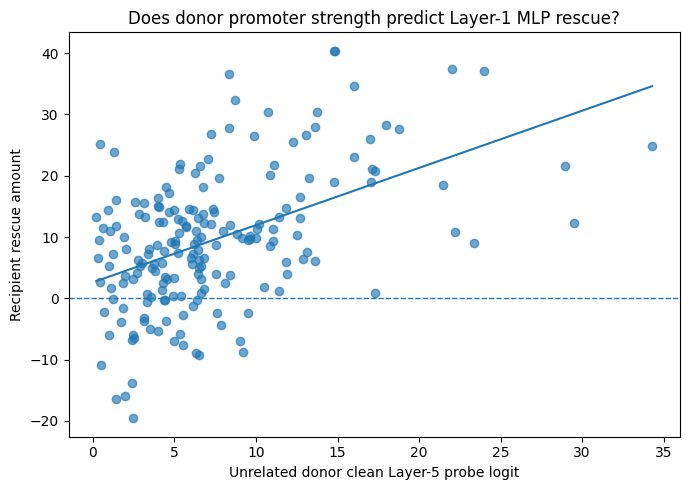


Saved donor-strength analysis to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


In [ ]:
from scipy.stats import spearmanr, pearsonr

# The unrelated donor index points into the 189-sequence rescue cohort.
donor_clean_logits = rescue_clean_logits[
    mlp_unrelated_donor_indices
]

donor_clean_probabilities = (
    rescue_clean_probabilities[
        mlp_unrelated_donor_indices
    ]
)

recipient_clean_logits = rescue_clean_logits
recipient_corrupt_logits = rescue_corrupt_logits
recipient_gaps = rescue_gaps

donor_strength_df = pd.DataFrame({
    "recipient_pair_index": np.arange(
        number_of_pairs
    ),
    "donor_pair_index": (
        mlp_unrelated_donor_indices
    ),
    "donor_clean_logit": donor_clean_logits,
    "donor_clean_probability": (
        donor_clean_probabilities
    ),
    "recipient_clean_logit": (
        recipient_clean_logits
    ),
    "recipient_corrupt_logit": (
        recipient_corrupt_logits
    ),
    "recipient_gap": recipient_gaps,
    "unrelated_rescue_amount": (
        mlp_unrelated_patch_df
        .sort_values("recipient_pair_index")[
            "unrelated_rescue_amount"
        ]
        .to_numpy()
    ),
    "unrelated_recovery_fraction": (
        mlp_unrelated_patch_df
        .sort_values("recipient_pair_index")[
            "unrelated_recovery_fraction"
        ]
        .to_numpy()
    ),
})

spearman_logit = spearmanr(
    donor_strength_df["donor_clean_logit"],
    donor_strength_df["unrelated_rescue_amount"],
)

pearson_logit = pearsonr(
    donor_strength_df["donor_clean_logit"],
    donor_strength_df["unrelated_rescue_amount"],
)

spearman_probability = spearmanr(
    donor_strength_df[
        "donor_clean_probability"
    ],
    donor_strength_df[
        "unrelated_rescue_amount"
    ],
)

donor_strength_summary = pd.DataFrame([
    {
        "predictor": "donor clean logit",
        "outcome": "unrelated rescue amount",
        "spearman_rho": spearman_logit.statistic,
        "spearman_p": spearman_logit.pvalue,
        "pearson_r": pearson_logit.statistic,
        "pearson_p": pearson_logit.pvalue,
    },
    {
        "predictor": "donor clean probability",
        "outcome": "unrelated rescue amount",
        "spearman_rho": (
            spearman_probability.statistic
        ),
        "spearman_p": (
            spearman_probability.pvalue
        ),
        "pearson_r": np.nan,
        "pearson_p": np.nan,
    },
])

display(donor_strength_summary)

# Compare rescue across donor-logit quartiles.
donor_strength_df["donor_logit_quartile"] = pd.qcut(
    donor_strength_df["donor_clean_logit"],
    q=4,
    labels=[
        "Q1 lowest",
        "Q2",
        "Q3",
        "Q4 highest",
    ],
)

donor_quartile_summary = (
    donor_strength_df
    .groupby(
        "donor_logit_quartile",
        observed=True,
    )
    .agg(
        number_of_pairs=(
            "unrelated_rescue_amount",
            "size",
        ),
        mean_donor_logit=(
            "donor_clean_logit",
            "mean",
        ),
        mean_rescue_amount=(
            "unrelated_rescue_amount",
            "mean",
        ),
        median_rescue_amount=(
            "unrelated_rescue_amount",
            "median",
        ),
        fraction_positive_rescue=(
            "unrelated_rescue_amount",
            lambda values: np.mean(values > 0),
        ),
    )
    .reset_index()
)

print("\nRescue by unrelated-donor logit quartile:")
display(donor_quartile_summary)

plt.figure(figsize=(7, 5))

plt.scatter(
    donor_strength_df["donor_clean_logit"],
    donor_strength_df[
        "unrelated_rescue_amount"
    ],
    alpha=0.65,
)

# Simple least-squares trend line for visualization.
trend_slope, trend_intercept = np.polyfit(
    donor_strength_df["donor_clean_logit"],
    donor_strength_df[
        "unrelated_rescue_amount"
    ],
    deg=1,
)

trend_x = np.linspace(
    donor_strength_df["donor_clean_logit"].min(),
    donor_strength_df["donor_clean_logit"].max(),
    100,
)

plt.plot(
    trend_x,
    trend_slope * trend_x + trend_intercept,
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

plt.xlabel("Unrelated donor clean Layer-5 probe logit")
plt.ylabel("Recipient rescue amount")
plt.title(
    "Does donor promoter strength predict Layer-1 MLP rescue?"
)

plt.tight_layout()

plt.savefig(
    CAUSAL_DIR
    / "layer1_mlp_donor_strength_vs_rescue.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

donor_strength_df.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_unrelated_donor_strength_results.csv",
    index=False,
)

donor_strength_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_donor_strength_correlation_summary.csv",
    index=False,
)

donor_quartile_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_donor_logit_quartile_summary.csv",
    index=False,
)

print(
    "\nSaved donor-strength analysis to:",
    CAUSAL_DIR,
)

# Cell 21 — Build a matched-size non-promoter donor pool

In [ ]:
GUE_DATASET_NAME = "leannmlindsey/GUE"
GUE_CONFIG_NAME = "prom_core_all"

gue_dataset = load_dataset(
    GUE_DATASET_NAME,
    GUE_CONFIG_NAME,
)

print(gue_dataset)
print("\nTest columns:", gue_dataset["test"].column_names)

# Inspect labels before selecting negatives.
test_df = gue_dataset["test"].to_pandas()

display(test_df.head())

print("\nTest label counts:")
display(
    test_df["label"]
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="count")
)

# Infer the sequence column.
negative_sequence_candidates = [
    "sequence",
    "seq",
    "text",
]

gue_sequence_column = next(
    (
        column
        for column in negative_sequence_candidates
        if column in test_df.columns
    ),
    None,
)

if gue_sequence_column is None:
    raise KeyError(
        "Could not identify the sequence column in GUE."
    )

# In prom_core_all, label 0 is the negative/non-promoter class.
negative_test_df = (
    test_df[test_df["label"] == 0]
    .copy()
    .reset_index(drop=True)
)

print("\nNegative test sequences:", len(negative_test_df))
print("Sequence column:", gue_sequence_column)

# Select exactly 189 negatives deterministically.
negative_donor_df = negative_test_df.sample(
    n=len(rescue_clean_sequences),
    random_state=SEED,
    replace=False,
).reset_index(drop=True)

negative_donor_sequences = (
    negative_donor_df[gue_sequence_column]
    .astype(str)
    .tolist()
)

assert len(negative_donor_sequences) == 189
assert all(
    len(sequence) == 70
    for sequence in negative_donor_sequences
)

# Score the negative donors with the fixed Layer-5 probe.
negative_donor_representations = (
    extract_layer5_representations(
        negative_donor_sequences,
        batch_size=32,
    )
)

negative_donor_logits = (
    layer5_probe.decision_function(
        negative_donor_representations
    )
)

negative_donor_probabilities = (
    layer5_probe.predict_proba(
        negative_donor_representations
    )[:, 1]
)

negative_donor_summary = pd.DataFrame([{
    "number_of_donors": len(negative_donor_sequences),
    "mean_probe_logit": negative_donor_logits.mean(),
    "median_probe_logit": np.median(
        negative_donor_logits
    ),
    "mean_probe_probability": (
        negative_donor_probabilities.mean()
    ),
    "fraction_probe_positive": np.mean(
        negative_donor_logits > 0
    ),
}])

print("\nNegative donor probe summary:")
display(negative_donor_summary)

negative_donor_output_df = pd.DataFrame({
    "negative_donor_index": np.arange(
        len(negative_donor_sequences)
    ),
    "sequence": negative_donor_sequences,
    "probe_logit": negative_donor_logits,
    "probe_probability": (
        negative_donor_probabilities
    ),
})

negative_donor_output_df.to_csv(
    CAUSAL_DIR / "negative_donor_pool.csv",
    index=False,
)

np.savez_compressed(
    CAUSAL_DIR / "negative_donor_probe_scores.npz",
    logits=negative_donor_logits,
    probabilities=negative_donor_probabilities,
)

print(
    "\nSaved negative donor pool to:",
    CAUSAL_DIR / "negative_donor_pool.csv",
)

README.md: 0.00B [00:00, ?B/s]

train.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

dev.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/47356 [00:00<?, ? examples/s]

...


Negative test sequences: 2952
Sequence column: sequence


Extracting Layer-5 representations:   0%|          | 0/6 [00:00<?, ?it/s]


Negative donor probe summary:


,number_of_donors,mean_probe_logit,median_probe_logit,mean_probe_probability,fraction_probe_positive
0,189,-3.255196,-3.505665,0.259395,0.243386



Saved negative donor pool to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/negative_donor_pool.csv


# Cell 22 — Patch non-promoter Layer-1 MLP donors into corrupt promoters


In [ ]:
negative_mlp_patch_rows = []

for recipient_index in tqdm(
    range(number_of_pairs),
    desc="Patching non-promoter Layer-1 MLP donors",
):
    donor_sequence = negative_donor_sequences[
        recipient_index
    ]

    recipient_corrupt_sequence = (
        rescue_corrupt_sequences[
            recipient_index
        ]
    )

    # Capture Layer-1 MLP output from the negative donor.
    donor_result = (
        run_single_sequence_and_capture_branch(
            donor_sequence,
            layer_index=0,
            branch_type="mlp",
        )
    )

    # Align donor token spans to recipient nucleotide positions.
    _, donor_offsets = get_token_offsets(
        donor_sequence
    )

    _, recipient_offsets = get_token_offsets(
        recipient_corrupt_sequence
    )

    negative_projection = (
        build_span_projection_matrix(
            clean_offsets=donor_offsets,
            corrupt_offsets=recipient_offsets,
        )
    )

    negative_patched_result = (
        run_single_sequence_with_branch_patch(
            corrupt_sequence=(
                recipient_corrupt_sequence
            ),
            layer_index=0,
            branch_type="mlp",
            clean_branch_output=(
                donor_result["branch_output"]
            ),
            projection_matrix=negative_projection,
        )
    )

    clean_logit = rescue_clean_logits[
        recipient_index
    ]

    corrupt_logit = rescue_corrupt_logits[
        recipient_index
    ]

    patched_logit = (
        negative_patched_result["logit"]
    )

    clean_corrupt_gap = (
        clean_logit - corrupt_logit
    )

    rescue_amount = (
        patched_logit - corrupt_logit
    )

    negative_mlp_patch_rows.append({
        "recipient_pair_index": recipient_index,
        "negative_donor_index": recipient_index,
        "negative_donor_probe_logit": (
            negative_donor_logits[
                recipient_index
            ]
        ),
        "negative_donor_probe_probability": (
            negative_donor_probabilities[
                recipient_index
            ]
        ),
        "clean_logit": clean_logit,
        "corrupt_logit": corrupt_logit,
        "patched_logit": patched_logit,
        "clean_corrupt_gap": clean_corrupt_gap,
        "rescue_amount": rescue_amount,
        "recovery_fraction": (
            rescue_amount / clean_corrupt_gap
        ),
        "patched_probability": (
            negative_patched_result[
                "probability"
            ]
        ),
        "mean_branch_change_norm": (
            negative_patched_result[
                "mean_branch_change_norm"
            ]
        ),
    })


negative_mlp_patch_df = pd.DataFrame(
    negative_mlp_patch_rows
)

display(negative_mlp_patch_df.head(10))

negative_mlp_summary = pd.DataFrame([{
    "donor_type": "non-promoter",
    "number_of_pairs": len(
        negative_mlp_patch_df
    ),
    "mean_donor_probe_logit": (
        negative_mlp_patch_df[
            "negative_donor_probe_logit"
        ].mean()
    ),
    "mean_patched_logit": (
        negative_mlp_patch_df[
            "patched_logit"
        ].mean()
    ),
    "mean_rescue_amount": (
        negative_mlp_patch_df[
            "rescue_amount"
        ].mean()
    ),
    "median_rescue_amount": (
        negative_mlp_patch_df[
            "rescue_amount"
        ].median()
    ),
    "mean_recovery_fraction": (
        negative_mlp_patch_df[
            "recovery_fraction"
        ].mean()
    ),
    "median_recovery_fraction": (
        negative_mlp_patch_df[
            "recovery_fraction"
        ].median()
    ),
    "fraction_positive_rescue": (
        negative_mlp_patch_df[
            "rescue_amount"
        ] > 0
    ).mean(),
    "fraction_at_least_50pct_recovery": (
        negative_mlp_patch_df[
            "recovery_fraction"
        ] >= 0.50
    ).mean(),
    "fraction_full_or_over_recovery": (
        negative_mlp_patch_df[
            "recovery_fraction"
        ] >= 1.0
    ).mean(),
    "fraction_patched_positive": (
        negative_mlp_patch_df[
            "patched_logit"
        ] > 0
    ).mean(),
}])

print("\nNon-promoter donor summary:")
display(negative_mlp_summary)

# Compare all three donor types on the same recipients.
donor_type_comparison_df = pd.DataFrame({
    "pair_index": np.arange(number_of_pairs),

    "matched_promoter_rescue": (
        layer1_mlp_patch_df
        .sort_values("pair_index")[
            "rescue_amount"
        ]
        .to_numpy()
    ),

    "unrelated_promoter_rescue": (
        mlp_unrelated_patch_df
        .sort_values(
            "recipient_pair_index"
        )[
            "unrelated_rescue_amount"
        ]
        .to_numpy()
    ),

    "non_promoter_rescue": (
        negative_mlp_patch_df
        .sort_values(
            "recipient_pair_index"
        )[
            "rescue_amount"
        ]
        .to_numpy()
    ),
})

donor_type_comparison_summary = pd.DataFrame([
    {
        "donor_type": "matched promoter",
        "mean_rescue": (
            donor_type_comparison_df[
                "matched_promoter_rescue"
            ].mean()
        ),
        "median_rescue": (
            donor_type_comparison_df[
                "matched_promoter_rescue"
            ].median()
        ),
        "fraction_positive": (
            donor_type_comparison_df[
                "matched_promoter_rescue"
            ] > 0
        ).mean(),
    },
    {
        "donor_type": "unrelated promoter",
        "mean_rescue": (
            donor_type_comparison_df[
                "unrelated_promoter_rescue"
            ].mean()
        ),
        "median_rescue": (
            donor_type_comparison_df[
                "unrelated_promoter_rescue"
            ].median()
        ),
        "fraction_positive": (
            donor_type_comparison_df[
                "unrelated_promoter_rescue"
            ] > 0
        ).mean(),
    },
    {
        "donor_type": "non-promoter",
        "mean_rescue": (
            donor_type_comparison_df[
                "non_promoter_rescue"
            ].mean()
        ),
        "median_rescue": (
            donor_type_comparison_df[
                "non_promoter_rescue"
            ].median()
        ),
        "fraction_positive": (
            donor_type_comparison_df[
                "non_promoter_rescue"
            ] > 0
        ).mean(),
    },
])

print("\nDonor-type comparison:")
display(donor_type_comparison_summary)

negative_mlp_patch_df.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_negative_donor_patch_results.csv",
    index=False,
)

negative_mlp_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_negative_donor_summary.csv",
    index=False,
)

donor_type_comparison_df.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_donor_type_pairwise_results.csv",
    index=False,
)

donor_type_comparison_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_donor_type_summary.csv",
    index=False,
)

print(
    "\nSaved negative-donor MLP results to:",
    CAUSAL_DIR,
)

Patching non-promoter Layer-1 MLP donors:   0%|          | 0/189 [00:00<?, ?it/s]

,recipient_pair_index,negative_donor_index,negative_donor_probe_logit,negative_donor_probe_probability,clean_logit,corrupt_logit,patched_logit,clean_corrupt_gap,rescue_amount,recovery_fraction,patched_probability,mean_branch_change_norm
0,0,0,2.096603,0.890573,5.393593,3.291286,15.054351,2.102307,11.763066,5.595312,1.000000,4.311878
1,1,1,-6.911253,0.000996,5.007429,3.685326,-2.633053,1.322102,-6.318379,-4.779039,0.067041,4.459310
2,2,2,1.905359,0.870497,6.289941,-0.207787,-3.870491,6.497728,-3.662704,-0.563690,0.020422,4.200266
3,3,3,-8.689655,0.000168,4.211724,1.402079,6.373430,2.809645,4.971352,1.769388,0.998297,4.417413
4,4,4,-3.454822,0.030625,2.431718,-7.186104,0.928788,9.617822,8.114892,0.843735,0.716829,4.435061
5,5,5,-1.692199,0.155487,6.169904,2.551906,-0.053058,3.617998,-2.604963,-0.720001,0.486739,3.967193
6,6,6,-7.350998,0.000642,10.836474,-8.675502,-5.545268,19.511976,3.130234,0.160426,0.003891,4.416349
7,7,7,-4.836030,0.007876,21.488038,13.312646,-4.939023,8.175392,-18.251669,-2.232513,0.007111,4.357200
8,8,8,-4.762709,0.008470,17.036306,6.511144,-5.189542,10.525162,-11.700686,-1.111687,0.005544,4.339698
9,9,9,-8.688930,0.000168,8.861694,-2.649134,0.427509,11.510828,3.076643,0.267282,0.605279,4.504863



Non-promoter donor summary:


,donor_type,number_of_pairs,mean_donor_probe_logit,mean_patched_logit,mean_rescue_amount,median_rescue_amount,mean_recovery_fraction,median_recovery_fraction,fraction_positive_rescue,fraction_at_least_50pct_recovery,fraction_full_or_over_recovery,fraction_patched_positive
0,non-promoter,189,-3.255196,1.313885,0.289538,-0.190699,-0.145387,-0.0281,0.492063,0.354497,0.232804,0.518519



Donor-type comparison:


,donor_type,mean_rescue,median_rescue,fraction_positive
0,matched promoter,10.809579,10.496404,0.899471
1,unrelated promoter,9.524232,9.304293,0.820106
2,non-promoter,0.289538,-0.190699,0.492063



Saved negative-donor MLP results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


# Cell 23 — Bootstrap donor-class specificity of Layer-1 MLP rescue

In [ ]:
N_BOOTSTRAPS = 5000
bootstrap_rng = np.random.default_rng(SEED)

matched_promoter_rescue = (
    donor_type_comparison_df[
        "matched_promoter_rescue"
    ].to_numpy()
)

unrelated_promoter_rescue = (
    donor_type_comparison_df[
        "unrelated_promoter_rescue"
    ].to_numpy()
)

non_promoter_rescue = (
    donor_type_comparison_df[
        "non_promoter_rescue"
    ].to_numpy()
)

matched_minus_negative = (
    matched_promoter_rescue
    - non_promoter_rescue
)

unrelated_minus_negative = (
    unrelated_promoter_rescue
    - non_promoter_rescue
)

matched_minus_unrelated = (
    matched_promoter_rescue
    - unrelated_promoter_rescue
)


def paired_bootstrap_summary(
    name,
    condition_a,
    condition_b,
):
    paired_difference = (
        condition_a - condition_b
    )

    bootstrap_means = np.empty(
        N_BOOTSTRAPS
    )

    for bootstrap_index in range(
        N_BOOTSTRAPS
    ):
        sampled_indices = (
            bootstrap_rng.integers(
                0,
                len(paired_difference),
                size=len(paired_difference),
            )
        )

        bootstrap_means[
            bootstrap_index
        ] = paired_difference[
            sampled_indices
        ].mean()

    return {
        "comparison": name,
        "number_of_pairs": len(
            paired_difference
        ),
        "condition_a_mean": (
            condition_a.mean()
        ),
        "condition_b_mean": (
            condition_b.mean()
        ),
        "mean_paired_difference": (
            paired_difference.mean()
        ),
        "median_paired_difference": (
            np.median(paired_difference)
        ),
        "ci_2.5": np.percentile(
            bootstrap_means,
            2.5,
        ),
        "ci_97.5": np.percentile(
            bootstrap_means,
            97.5,
        ),
        "fraction_a_greater": np.mean(
            paired_difference > 0
        ),
    }


donor_class_bootstrap_summary = pd.DataFrame([
    paired_bootstrap_summary(
        (
            "matched promoter minus "
            "non-promoter donor"
        ),
        matched_promoter_rescue,
        non_promoter_rescue,
    ),
    paired_bootstrap_summary(
        (
            "unrelated promoter minus "
            "non-promoter donor"
        ),
        unrelated_promoter_rescue,
        non_promoter_rescue,
    ),
    paired_bootstrap_summary(
        (
            "matched promoter minus "
            "unrelated promoter donor"
        ),
        matched_promoter_rescue,
        unrelated_promoter_rescue,
    ),
])

display(donor_class_bootstrap_summary)


# Bootstrap the absolute non-promoter effect.
negative_bootstrap_means = np.empty(
    N_BOOTSTRAPS
)

for bootstrap_index in range(
    N_BOOTSTRAPS
):
    sampled_indices = (
        bootstrap_rng.integers(
            0,
            len(non_promoter_rescue),
            size=len(non_promoter_rescue),
        )
    )

    negative_bootstrap_means[
        bootstrap_index
    ] = non_promoter_rescue[
        sampled_indices
    ].mean()


non_promoter_absolute_summary = pd.DataFrame([{
    "donor_type": "non-promoter",
    "mean_rescue": (
        non_promoter_rescue.mean()
    ),
    "median_rescue": np.median(
        non_promoter_rescue
    ),
    "ci_2.5": np.percentile(
        negative_bootstrap_means,
        2.5,
    ),
    "ci_97.5": np.percentile(
        negative_bootstrap_means,
        97.5,
    ),
    "fraction_positive": np.mean(
        non_promoter_rescue > 0
    ),
}])

print(
    "\nAbsolute non-promoter donor effect:"
)

display(non_promoter_absolute_summary)


# Compact interpretation.
for _, row in (
    donor_class_bootstrap_summary
    .iterrows()
):
    if row["ci_2.5"] > 0:
        result = (
            "condition A reliably greater"
        )
    elif row["ci_97.5"] < 0:
        result = (
            "condition B reliably greater"
        )
    else:
        result = (
            "difference statistically uncertain"
        )

    print(
        f"{row['comparison']}: {result}"
    )


donor_class_bootstrap_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_donor_class_bootstrap_summary.csv",
    index=False,
)

non_promoter_absolute_summary.to_csv(
    CAUSAL_DIR
    / "layer1_mlp_non_promoter_absolute_bootstrap_summary.csv",
    index=False,
)

print(
    "\nSaved donor-class bootstrap results to:",
    CAUSAL_DIR,
)

,comparison,number_of_pairs,condition_a_mean,condition_b_mean,mean_paired_difference,median_paired_difference,ci_2.5,ci_97.5,fraction_a_greater
0,matched promoter minus non-promoter donor,189,10.809579,0.289538,10.520040,8.979037,8.880171,12.192920,0.825397
1,unrelated promoter minus non-promoter donor,189,9.524232,0.289538,9.234694,8.875524,7.416012,11.036970,0.798942
2,matched promoter minus unrelated promoter donor,189,10.809579,9.524232,1.285346,0.265908,-0.727624,3.252883,0.513228



Absolute non-promoter donor effect:


,donor_type,mean_rescue,median_rescue,ci_2.5,ci_97.5,fraction_positive
0,non-promoter,0.289538,-0.190699,-1.127242,1.696794,0.492063


matched promoter minus non-promoter donor: condition A reliably greater
unrelated promoter minus non-promoter donor: condition A reliably greater
matched promoter minus unrelated promoter donor: difference statistically uncertain

Saved donor-class bootstrap results to: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions


In [ ]:
# Cell 24 — Final causal-intervention summary

causal_result_summary = pd.DataFrame([
    {
        "experiment": "L1H9 matched clean patch",
        "mean_rescue": (
            l1h9_patch_df["rescue_amount"].mean()
        ),
        "ci_2.5": (
            absolute_rescue_summary["ci_2.5"].iloc[0]
        ),
        "ci_97.5": (
            absolute_rescue_summary["ci_97.5"].iloc[0]
        ),
        "fraction_positive": (
            l1h9_patch_df["rescue_amount"] > 0
        ).mean(),
        "interpretation": (
            "No absolute rescue; single head is not "
            "independently sufficient."
        ),
    },
    {
        "experiment": "Layer-1 attention matched patch",
        "mean_rescue": (
            layer1_attention_patch_df[
                "rescue_amount"
            ].mean()
        ),
        "ci_2.5": (
            layer1_attention_bootstrap_summary[
                "ci_2.5"
            ].iloc[0]
        ),
        "ci_97.5": (
            layer1_attention_bootstrap_summary[
                "ci_97.5"
            ].iloc[0]
        ),
        "fraction_positive": (
            layer1_attention_patch_df[
                "rescue_amount"
            ] > 0
        ).mean(),
        "interpretation": (
            "Whole attention branch does not restore "
            "the promoter-associated readout."
        ),
    },
    {
        "experiment": "Layer-1 MLP matched promoter patch",
        "mean_rescue": (
            matched_promoter_rescue.mean()
        ),
        "ci_2.5": (
            layer1_mlp_bootstrap_summary[
                "ci_2.5"
            ].iloc[0]
        ),
        "ci_97.5": (
            layer1_mlp_bootstrap_summary[
                "ci_97.5"
            ].iloc[0]
        ),
        "fraction_positive": np.mean(
            matched_promoter_rescue > 0
        ),
        "interpretation": (
            "Strong promoter-associated signal delivery."
        ),
    },
    {
        "experiment": "Layer-1 MLP unrelated promoter patch",
        "mean_rescue": (
            unrelated_promoter_rescue.mean()
        ),
        "ci_2.5": (
            mlp_specificity_summary[
                "unrelated_ci_2.5"
            ].iloc[0]
        ),
        "ci_97.5": (
            mlp_specificity_summary[
                "unrelated_ci_97.5"
            ].iloc[0]
        ),
        "fraction_positive": np.mean(
            unrelated_promoter_rescue > 0
        ),
        "interpretation": (
            "Promoter-class signal transfers across "
            "different promoter sequences."
        ),
    },
    {
        "experiment": "Layer-1 MLP non-promoter patch",
        "mean_rescue": (
            non_promoter_rescue.mean()
        ),
        "ci_2.5": (
            non_promoter_absolute_summary[
                "ci_2.5"
            ].iloc[0]
        ),
        "ci_97.5": (
            non_promoter_absolute_summary[
                "ci_97.5"
            ].iloc[0]
        ),
        "fraction_positive": np.mean(
            non_promoter_rescue > 0
        ),
        "interpretation": (
            "No reliable rescue from non-promoter donors."
        ),
    },
])

display(causal_result_summary)

causal_result_summary.to_csv(
    CAUSAL_DIR / "causal_intervention_summary.csv",
    index=False,
)

final_notebook4_conclusions = """
# Notebook 4: Promoter Causal Interventions

## Experimental target

All interventions were evaluated using the fixed Layer-5
diagnostic promoter probe from Notebook 1. This probe is not
a native DNABERT-2 promoter classifier.

The primary causal cohort contained 189 true promoter
sequences for which exact dinucleotide-preserving corruption
reduced the clean probe logit by at least one unit.

The cohort had:

- mean clean logit: 7.393
- mean corrupted logit: 1.024
- mean clean-corrupt gap: 6.369

## Tokenization alignment

Clean and corrupted sequences did not share DNABERT-2 BPE
boundaries:

- only 59/189 pairs had equal token counts
- 0/189 pairs had identical token-span patterns

Therefore, clean activations were projected into corrupted
token positions using overlap-weighted absolute nucleotide
span alignment.

Self-patching controls reproduced unpatched logits to within
approximately 3e-5, confirming correct implementation.

## L1H9

Clean L1H9 patching did not rescue promoter evidence:

- mean rescue: -2.384
- 95% CI: [-3.139, -1.596]
- positive rescue: 31.2%

Matched clean donors did not reliably outperform unrelated
clean promoter donors.

Thus, L1H9 is strongly sensitivity-associated in clean-run
mean replacement but is not independently sufficient to
restore promoter evidence under global dinucleotide
corruption.

## Layer-1 attention

Patching the full Layer-1 attention branch also failed to
produce average rescue:

- mean rescue: -0.806
- 95% CI: [-1.363, -0.248]
- positive rescue: 38.6%

This indicates that coordinated Layer-1 attention output alone
is not sufficient in the globally corrupted residual stream.

## Layer-1 MLP

Patching matched clean Layer-1 MLP outputs produced strong
over-restoration:

- mean rescue: 10.810
- 95% CI: [9.602, 12.009]
- positive rescue: 89.9%
- median recovery fraction: 1.731

However, unrelated clean promoter donors produced a similar
effect:

- mean rescue: 9.524
- matched-minus-unrelated difference: 1.285
- 95% CI: [-0.728, 3.253]

Therefore, most of the Layer-1 MLP effect is promoter-class
specific rather than matched-sequence specific.

## Donor-strength dependence

Among unrelated promoter donors, donor probe strength
predicted rescue magnitude:

- Spearman rho: 0.441
- Pearson r: 0.486

Mean rescue increased across donor-strength quartiles from
3.37 in the lowest quartile to 18.41 in the highest quartile.

## Non-promoter control

Non-promoter Layer-1 MLP donors produced no reliable average
rescue:

- mean rescue: 0.290
- median rescue: -0.191
- 95% CI: [-1.127, 1.697]

Both matched and unrelated promoter donors strongly exceeded
non-promoter donors:

- matched minus non-promoter: 10.520
  95% CI [8.880, 12.193]

- unrelated promoter minus non-promoter: 9.235
  95% CI [7.416, 11.037]

## Supported mechanistic model

The promoter-associated Layer-5 diagnostic representation is
built early in DNABERT-2.

Layer-1 attention components, especially L1H9 and L1H2, are
strongly necessary-like under clean-run mean replacement, but
their clean outputs do not independently restore the signal in
a globally corrupted run.

Layer-1 MLP output contains a transferable promoter-associated
representation. Promoter-derived MLP activations strongly
increase downstream promoter evidence, whereas non-promoter
MLP activations have no reliable average effect.

The Layer-1 MLP signal is predominantly class-level rather
than sequence-specific.

## Interpretation boundary

These findings support representation delivery to a fixed
diagnostic probe. They do not establish:

- a complete faithful circuit,
- native promoter classification by DNABERT-2,
- the biological motif encoded by the Layer-1 MLP,
- or exact token-level causal correspondence because BPE
  alignment required nucleotide-span projection.

## Next experiment

Characterize what biological sequence feature controls the
Layer-1 MLP promoter direction.

Priority analyses:

1. correlate MLP rescue with GC content, CpG density, TATA-box
   presence, and promoter subclasses;
2. test controlled motif insertion and deletion;
3. identify low-rank directions in Layer-1 MLP output;
4. test whether projecting only the promoter-associated
   direction reproduces the donor-class effect;
5. separate generic promoter evidence from sequence-specific
   information.
"""

conclusion_path = (
    CAUSAL_DIR / "NOTEBOOK_4_CONCLUSIONS.md"
)

with open(conclusion_path, "w") as file:
    file.write(
        final_notebook4_conclusions.strip()
    )

print("\nSaved causal summary to:")
print(
    CAUSAL_DIR
    / "causal_intervention_summary.csv"
)

print("\nSaved conclusions to:")
print(conclusion_path)

print("\nNotebook 4 complete.")

,experiment,mean_rescue,ci_2.5,ci_97.5,fraction_positive,interpretation
0,L1H9 matched clean patch,-2.384057,-3.139282,-1.595806,0.312169,No absolute rescue; single head is not indepen...
1,Layer-1 attention matched patch,-0.805809,-1.363113,-0.248188,0.386243,Whole attention branch does not restore the pr...
2,Layer-1 MLP matched promoter patch,10.809579,9.601774,12.009045,0.899471,Strong promoter-associated signal delivery.
3,Layer-1 MLP unrelated promoter patch,9.524232,7.979268,11.106509,0.820106,Promoter-class signal transfers across differe...
4,Layer-1 MLP non-promoter patch,0.289538,-1.127242,1.696794,0.492063,No reliable rescue from non-promoter donors.



Saved causal summary to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/causal_intervention_summary.csv

Saved conclusions to:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_causal_interventions/NOTEBOOK_4_CONCLUSIONS.md

Notebook 4 complete.
